In [2]:
# Google Drive 연결
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# YOLO 라이브러리 다시 설치
!pip install -q ultralytics opencv-python pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 289.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 33.9 MB/s eta 0:00:00


In [4]:
# YOLO 학습을 위한 라이브러리 설치
!pip install -q ultralytics opencv-python supervision pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 218.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.6/251.6 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 7.2 MB/s eta 0:00:00


In [6]:
!pip install -q ultralytics

from ultralytics import YOLO
import ultralytics

ultralytics.checks()

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.7/112.6 GB disk)


In [7]:
# 데이터셋 압축 파일 경로 설정
from pathlib import Path

DAWN_ZIP = Path("/content/DAWN.yolov8.zip")
MEMBER_ZIP = Path("/content/bdd100k_0808.zip")

print("DAWN 파일 존재 여부:", DAWN_ZIP.exists())
print("조원 데이터 파일 존재 여부:", MEMBER_ZIP.exists())

DAWN 파일 존재 여부: True
조원 데이터 파일 존재 여부: True


In [9]:
# 数据集解压
import zipfile
import shutil
from pathlib import Path

DAWN_ZIP = Path("/content/DAWN.yolov8.zip")
MEMBER_ZIP = Path("/content/bdd100k_0808.zip")

DATA_ROOT = Path("/content/datasets")
DAWN_DIR = DATA_ROOT / "DAWN"
MEMBER_DIR = DATA_ROOT / "MEMBER"

# 如果之前解压过，先清理，避免文件混乱
if DAWN_DIR.exists():
    shutil.rmtree(DAWN_DIR)

if MEMBER_DIR.exists():
    shutil.rmtree(MEMBER_DIR)

DAWN_DIR.mkdir(parents=True, exist_ok=True)
MEMBER_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DAWN_ZIP, "r") as zip_ref:
    zip_ref.extractall(DAWN_DIR)

with zipfile.ZipFile(MEMBER_ZIP, "r") as zip_ref:
    zip_ref.extractall(MEMBER_DIR)

print("DAWN 解压完成:", DAWN_DIR)
print("组员数据解压完成:", MEMBER_DIR)

DAWN 解压完成: /content/datasets/DAWN
组员数据解压完成: /content/datasets/MEMBER


In [10]:
# 데이터셋 파일 구조 보기
import os
from pathlib import Path

for root, dirs, files in os.walk("/content/datasets"):
    level = root.replace("/content/datasets", "").count(os.sep)
    indent = "  " * level
    print(indent + Path(root).name + "/")

    sub_indent = "  " * (level + 1)
    for file in files[:5]:
        print(sub_indent + file)

    if level >= 3:
        dirs[:] = []

datasets/
  MEMBER/
    __MACOSX/
      ._bdd100k_0808
      bdd100k_0808/
        ._data.yaml
        ._train
        ._README.dataset.txt
        ._README.roboflow.txt
        ._valid
    bdd100k_0808/
      README.roboflow.txt
      README.dataset.txt
      .DS_Store
      data.yaml
      train/
        .DS_Store
      valid/
  DAWN/
    README.roboflow.txt
    README.dataset.txt
    data.yaml
    train/
      images/
        foggy-031_jpg.rf.wAtyd12KF0oqdT4MWg3g.jpg
        rain_storm-261_jpg.rf.qfWtflgmDryVPmbvH7TM.jpg
        snow_storm-215_jpg.rf.sx56zZhm3S6RfcmjZIMO.jpg
        rain_storm-319_jpg.rf.6oSKeZBPhsPntH9VD8cO.jpg
        sand_storm-197_jpg.rf.yvaihZmtyvqDW4u332GA.jpg
      labels/
        sand_storm_g2_-086_jpg.rf.22glfzQ4bu6yy6lpRxKb.txt
        foggy-004_jpg.rf.AthRvwdXXsI3J6uHADfz.txt
        haze-097_jpg.rf.QkexgvJS5Jj9kRrgbJg9.txt
        sand_storm-204_jpg.rf.aqPkYKb0GrCZjqesdsUy.txt
        rain_storm-078_jpg.rf.CNegImFcLwjPfi8zndVi.txt
    valid/
      images

In [12]:
# 查找所有 data.yaml
yaml_files = list(Path("/content/datasets").rglob("*.yaml"))

print("yaml 文件：")
for i, y in enumerate(yaml_files):
    print(i, y)

yaml 文件：
0 /content/datasets/DAWN/data.yaml
1 /content/datasets/MEMBER/bdd100k_0808/data.yaml
2 /content/datasets/MEMBER/__MACOSX/bdd100k_0808/._data.yaml


In [13]:
# 두 데이터셋 압축 해제
import shutil
import zipfile
from pathlib import Path

dawn_extract = Path("/content/dawn")
member_extract = Path("/content/member")

# 기존 폴더 삭제 후 새로 생성
for folder in [dawn_extract, member_extract]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)

# 압축 해제 함수
def unzip_file(zip_path, extract_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

unzip_file(DAWN_ZIP, dawn_extract)
unzip_file(MEMBER_ZIP, member_extract)

print("압축 해제 완료")

print("\nDAWN 폴더:")
!ls /content/dawn

print("\n조원 데이터 폴더:")
!ls /content/member

압축 해제 완료

DAWN 폴더:
data.yaml  README.dataset.txt  README.roboflow.txt  train  valid

조원 데이터 폴더:
bdd100k_0808  __MACOSX


In [14]:
# data.yaml 위치 자동 확인
from pathlib import Path
import yaml

def find_dataset_root(base_path):
    base_path = Path(base_path)
    yaml_files = list(base_path.rglob("data.yaml"))

    if len(yaml_files) == 0:
        raise FileNotFoundError(f"{base_path} 안에서 data.yaml을 찾을 수 없습니다.")

    return yaml_files[0].parent

dawn_root = find_dataset_root("/content/dawn")
member_root = find_dataset_root("/content/member")

print("DAWN 데이터셋 경로:", dawn_root)
print("조원 데이터셋 경로:", member_root)

print("\nDAWN data.yaml 내용:")
!cat "{dawn_root}/data.yaml"

print("\n조원 data.yaml 내용:")
!cat "{member_root}/data.yaml"

DAWN 데이터셋 경로: /content/dawn
조원 데이터셋 경로: /content/member/bdd100k_0808

DAWN data.yaml 내용:
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 7
names: ['bicycle', 'bus', 'car', 'motorcycle', 'person', 'train', 'truck']

roboflow:
  workspace: -qezws
  project: dawn-urv49-pekwk
  version: dataset
  license: CC BY 4.0
  url: https://universe.roboflow.com/-qezws/dawn-urv49-pekwk/dataset/dataset
조원 data.yaml 내용:
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 10
names: ['bike', 'bus', 'car', 'motor', 'person', 'rider', 'traffic light', 'traffic sign', 'train', 'truck']

roboflow:
  workspace: bdd100k-zljaf
  project: bdd100k_0808
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/bdd100k-zljaf/bdd100k_0808/dataset/1

In [15]:
# 데이터셋 구조 확인
from pathlib import Path

def check_structure(root, dataset_name):
    root = Path(root)
    print(f"\n[{dataset_name}] 데이터셋 구조 확인")

    for split in ["train", "valid", "test"]:
        image_dir = root / split / "images"
        label_dir = root / split / "labels"

        print(f"\n{split}")
        print("images 폴더 존재:", image_dir.exists())
        print("labels 폴더 존재:", label_dir.exists())

        if image_dir.exists():
            print("이미지 개수:", len(list(image_dir.glob("*"))))
        if label_dir.exists():
            print("라벨 개수:", len(list(label_dir.glob("*.txt"))))

check_structure(dawn_root, "DAWN")
check_structure(member_root, "조원 데이터")


[DAWN] 데이터셋 구조 확인

train
images 폴더 존재: True
labels 폴더 존재: True
이미지 개수: 794
라벨 개수: 794

valid
images 폴더 존재: True
labels 폴더 존재: True
이미지 개수: 205
라벨 개수: 205

test
images 폴더 존재: False
labels 폴더 존재: False

[조원 데이터] 데이터셋 구조 확인

train
images 폴더 존재: True
labels 폴더 존재: True
이미지 개수: 7999
라벨 개수: 7999

valid
images 폴더 존재: True
labels 폴더 존재: True
이미지 개수: 1999
라벨 개수: 1999

test
images 폴더 존재: False
labels 폴더 존재: False


In [16]:
# 10개 클래스 기준으로 데이터셋 병합
import shutil
from pathlib import Path

dawn_root = Path(dawn_root)
member_root = Path(member_root)
merged_root = Path("/content/merged_road_10cls")

# 기존 병합 폴더 삭제
if merged_root.exists():
    shutil.rmtree(merged_root)

# 새 병합 폴더 생성
for split in ["train", "valid", "test"]:
    (merged_root / split / "images").mkdir(parents=True, exist_ok=True)
    (merged_root / split / "labels").mkdir(parents=True, exist_ok=True)

# DAWN 7개 클래스 번호를 BDD100K 10개 클래스 번호로 변환
# DAWN: 0 bicycle, 1 bus, 2 car, 3 motorcycle, 4 person, 5 train, 6 truck
# BDD100K: 0 bike, 1 bus, 2 car, 3 motor, 4 person, 5 rider, 6 traffic light, 7 traffic sign, 8 train, 9 truck
dawn_to_10cls = {
    0: 0,  # bicycle -> bike
    1: 1,  # bus -> bus
    2: 2,  # car -> car
    3: 3,  # motorcycle -> motor
    4: 4,  # person -> person
    5: 8,  # train -> train
    6: 9   # truck -> truck
}

image_exts = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

def copy_member_dataset(src_root, prefix):
    """
    조원 데이터셋은 이미 10개 클래스 기준이므로 그대로 복사
    """
    src_root = Path(src_root)

    for split in ["train", "valid", "test"]:
        image_dir = src_root / split / "images"
        label_dir = src_root / split / "labels"

        if not image_dir.exists():
            continue

        for img_path in image_dir.iterdir():
            if img_path.suffix.lower() not in image_exts:
                continue

            new_img_name = f"{prefix}_{split}_{img_path.name}"
            new_img_path = merged_root / split / "images" / new_img_name
            shutil.copy(img_path, new_img_path)

            old_label_path = label_dir / f"{img_path.stem}.txt"
            new_label_path = merged_root / split / "labels" / f"{Path(new_img_name).stem}.txt"

            if old_label_path.exists():
                shutil.copy(old_label_path, new_label_path)
            else:
                new_label_path.write_text("")

def copy_and_convert_dawn_dataset(src_root, prefix):
    """
    DAWN 데이터셋은 7개 클래스이므로 10개 클래스 기준으로 라벨 번호를 변환 후 복사
    """
    src_root = Path(src_root)

    for split in ["train", "valid"]:
        image_dir = src_root / split / "images"
        label_dir = src_root / split / "labels"

        if not image_dir.exists():
            continue

        for img_path in image_dir.iterdir():
            if img_path.suffix.lower() not in image_exts:
                continue

            new_img_name = f"{prefix}_{split}_{img_path.name}"
            new_img_path = merged_root / split / "images" / new_img_name
            shutil.copy(img_path, new_img_path)

            old_label_path = label_dir / f"{img_path.stem}.txt"
            new_label_path = merged_root / split / "labels" / f"{Path(new_img_name).stem}.txt"

            converted_lines = []

            if old_label_path.exists():
                with open(old_label_path, "r") as f:
                    lines = f.readlines()

                for line in lines:
                    parts = line.strip().split()

                    if len(parts) < 5:
                        continue

                    old_cls = int(float(parts[0]))

                    if old_cls in dawn_to_10cls:
                        new_cls = dawn_to_10cls[old_cls]
                        parts[0] = str(new_cls)
                        converted_lines.append(" ".join(parts))

            with open(new_label_path, "w") as f:
                f.write("\n".join(converted_lines))

# 병합 실행
copy_member_dataset(member_root, "bdd")
copy_and_convert_dawn_dataset(dawn_root, "dawn")

print("10개 클래스 기준 데이터셋 병합 완료")

10개 클래스 기준 데이터셋 병합 완료


In [17]:
# 병합 데이터셋용 data.yaml 생성
yaml_text = """
path: /content/merged_road_10cls
train: train/images
val: valid/images
test: test/images

nc: 10
names:
  0: bike
  1: bus
  2: car
  3: motor
  4: person
  5: rider
  6: traffic light
  7: traffic sign
  8: train
  9: truck
"""

with open("/content/merged_road_10cls/data.yaml", "w") as f:
    f.write(yaml_text)

print("새 data.yaml 생성 완료")
!cat /content/merged_road_10cls/data.yaml

새 data.yaml 생성 완료

path: /content/merged_road_10cls
train: train/images
val: valid/images
test: test/images

nc: 10
names:
  0: bike
  1: bus
  2: car
  3: motor
  4: person
  5: rider
  6: traffic light
  7: traffic sign
  8: train
  9: truck


In [18]:
# 병합 후 이미지와 라벨 개수 확인
from pathlib import Path

for split in ["train", "valid", "test"]:
    image_dir = Path(f"/content/merged_road_10cls/{split}/images")
    label_dir = Path(f"/content/merged_road_10cls/{split}/labels")

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"{split} 이미지 개수:", len(images))
    print(f"{split} 라벨 개수:", len(labels))
    print("-" * 30)

train 이미지 개수: 8793
train 라벨 개수: 8793
------------------------------
valid 이미지 개수: 2204
valid 라벨 개수: 2204
------------------------------
test 이미지 개수: 0
test 라벨 개수: 0
------------------------------


In [19]:
# 라벨 번호가 0~9 범위 안에 있는지 확인
from pathlib import Path
from collections import Counter

label_counter = Counter()
wrong_labels = []

for label_path in Path("/content/merged_road_10cls").glob("**/labels/*.txt"):
    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) >= 5:
                cls_id = int(float(parts[0]))
                label_counter[cls_id] += 1

                if cls_id < 0 or cls_id > 9:
                    wrong_labels.append((str(label_path), cls_id))

class_names = ["bike", "bus", "car", "motor", "person", "rider", "traffic light", "traffic sign", "train", "truck"]

print("클래스별 객체 수:")
for cls_id, cls_name in enumerate(class_names):
    print(cls_id, cls_name, ":", label_counter[cls_id])

print("\n잘못된 라벨 개수:", len(wrong_labels))

if wrong_labels:
    print("잘못된 라벨 예시:")
    print(wrong_labels[:10])

클래스별 객체 수:
0 bike : 1033
1 bus : 1758
2 car : 108829
3 motor : 532
4 person : 13730
5 rider : 649
6 traffic light : 26881
7 traffic sign : 34902
8 train : 16
9 truck : 4878

잘못된 라벨 개수: 0


/content/merged_road_10cls/train/images/dawn_train_sand_storm-991_jpg.rf.z7Ll4Ll3PA66r0wcH5ri.jpg


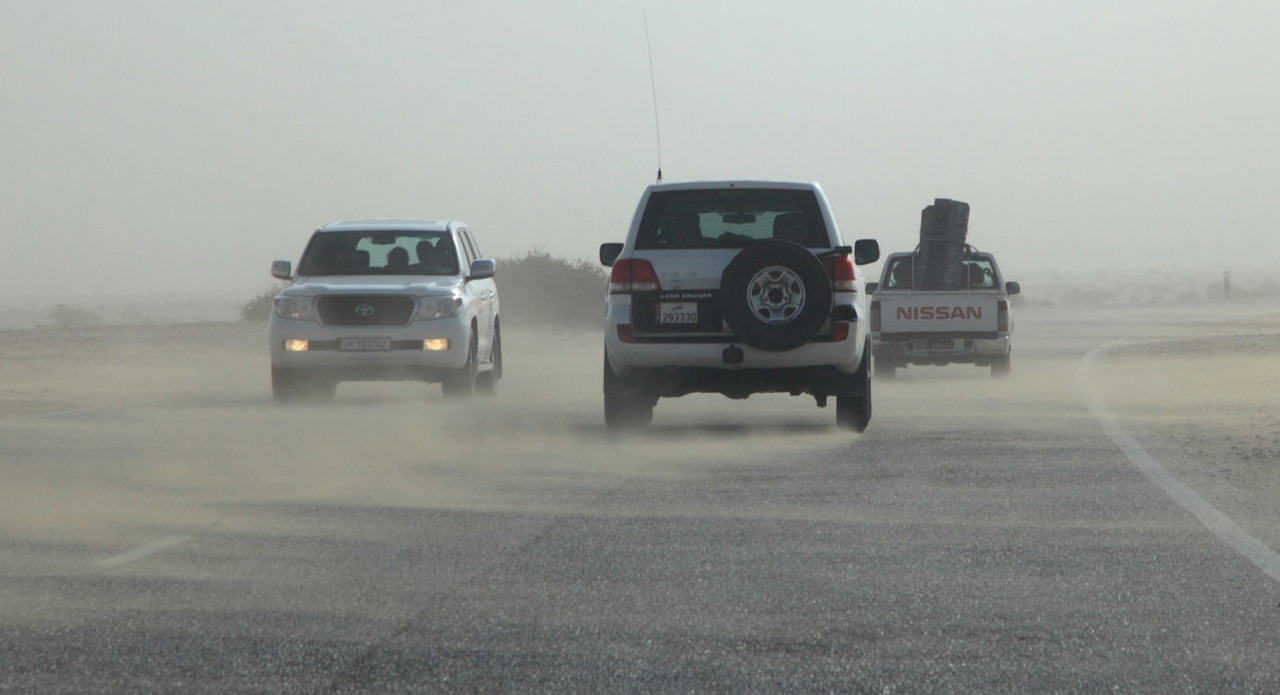

/content/merged_road_10cls/train/images/bdd_train_c66a2cb5-80c469d8_jpg.rf.48ff911b9c061989912a76a8fda821ce.jpg


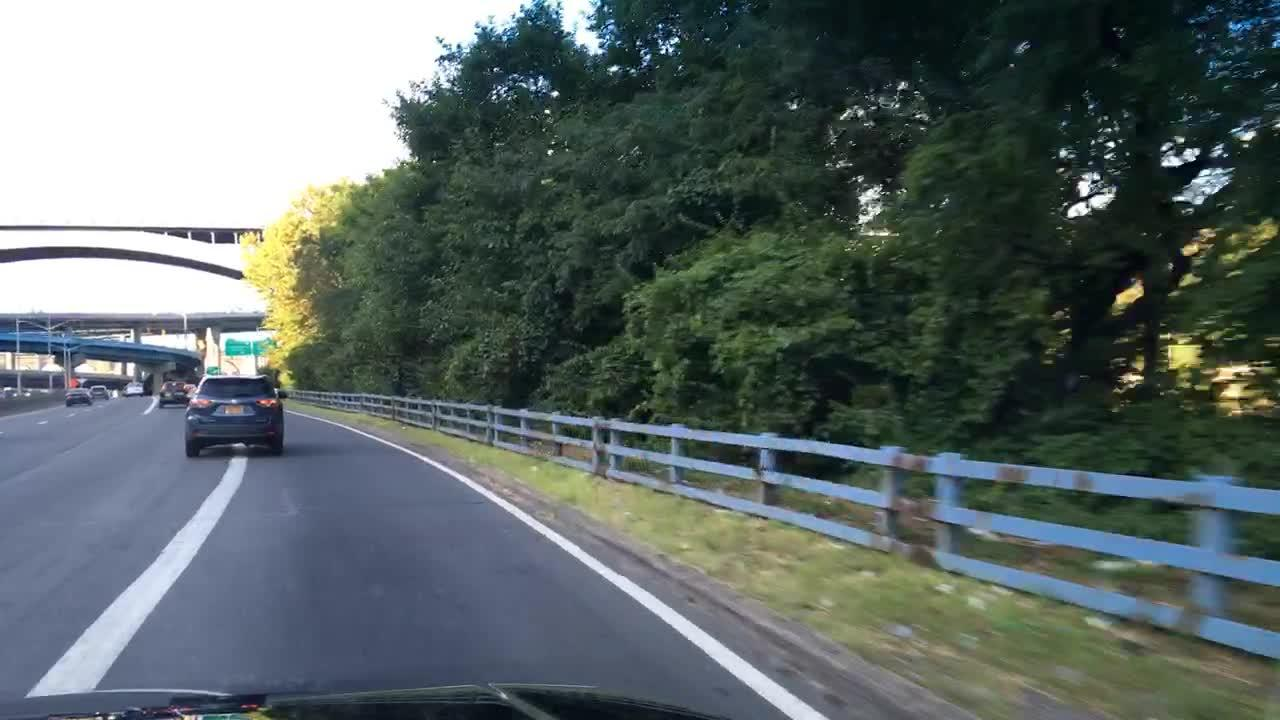

/content/merged_road_10cls/train/images/bdd_train_ca2fb80b-9d22e350_jpg.rf.1813d24f94ea75ce61fd0e5c01b0e95c.jpg


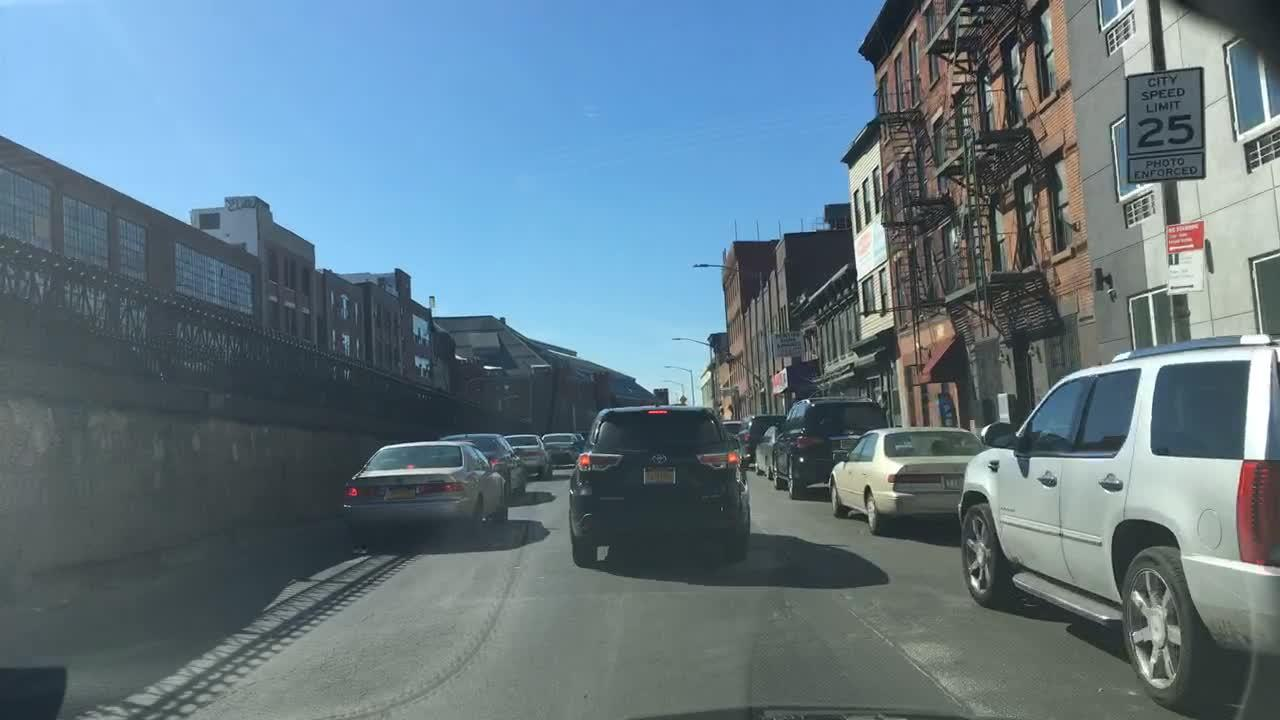

In [20]:
# 병합된 이미지 일부 확인
from IPython.display import Image, display
from pathlib import Path

sample_images = list(Path("/content/merged_road_10cls/train/images").glob("*"))[:3]

for img in sample_images:
    print(img)
    display(Image(filename=str(img)))

In [25]:
from pathlib import Path
import yaml
import shutil
import os

# 데이터셋 경로 설정
DAWN_ROOT = Path("/content/datasets/DAWN")
MEMBER_ROOT = Path("/content/datasets/MEMBER/bdd100k_0808")

# 변환된 조원 데이터가 저장될 경로
MEMBER_CONVERTED_ROOT = Path("/content/datasets/MEMBER_converted_to_DAWN")

# 기존 변환 폴더가 있으면 삭제
if MEMBER_CONVERTED_ROOT.exists():
    shutil.rmtree(MEMBER_CONVERTED_ROOT)

MEMBER_CONVERTED_ROOT.mkdir(parents=True, exist_ok=True)

# yaml의 names 형식 정리
def normalize_names(names):
    if isinstance(names, dict):
        return [names[k] for k in sorted(names.keys(), key=lambda x: int(x))]
    return list(names)

# DAWN 클래스 읽기
with open(DAWN_ROOT / "data.yaml", "r", encoding="utf-8") as f:
    dawn_data = yaml.safe_load(f)

with open(MEMBER_ROOT / "data.yaml", "r", encoding="utf-8") as f:
    member_data = yaml.safe_load(f)

dawn_names = normalize_names(dawn_data["names"])
member_names = normalize_names(member_data["names"])

print("DAWN 클래스:", dawn_names)
print("조원 데이터 클래스:", member_names)

# 조원 데이터 클래스를 DAWN 클래스에 맞게 변환
# traffic light, traffic sign은 DAWN에 없기 때문에 제외
name_mapping = {
    "bike": "bicycle",
    "bus": "bus",
    "car": "car",
    "motor": "motorcycle",
    "person": "person",
    "rider": "person",
    "train": "train",
    "truck": "truck"
}

# 기존 클래스 번호를 새로운 클래스 번호로 변환
oldid_to_newid = {}

for old_id, old_name in enumerate(member_names):
    if old_name in name_mapping:
        new_name = name_mapping[old_name]
        if new_name in dawn_names:
            new_id = dawn_names.index(new_name)
            oldid_to_newid[old_id] = new_id

print("\n클래스 변환 규칙:")
for old_id, new_id in oldid_to_newid.items():
    print(f"{old_id} {member_names[old_id]}  →  {new_id} {dawn_names[new_id]}")

# 이미지 확장자
image_exts = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

# split별로 label 변환
def convert_split(split):
    src_img_dir = MEMBER_ROOT / split / "images"
    src_label_dir = MEMBER_ROOT / split / "labels"

    dst_img_dir = MEMBER_CONVERTED_ROOT / split / "images"
    dst_label_dir = MEMBER_CONVERTED_ROOT / split / "labels"

    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_label_dir.mkdir(parents=True, exist_ok=True)

    if not src_img_dir.exists():
        print(f"{split}: 이미지 폴더가 없습니다. 건너뜁니다.")
        return

    image_paths = []
    for ext in image_exts:
        image_paths.extend(list(src_img_dir.glob(f"*{ext}")))
        image_paths.extend(list(src_img_dir.glob(f"*{ext.upper()}")))

    kept_images = 0
    kept_boxes = 0

    for img_path in image_paths:
        label_path = src_label_dir / f"{img_path.stem}.txt"
        new_lines = []

        if label_path.exists():
            with open(label_path, "r", encoding="utf-8") as f:
                lines = f.readlines()

            for line in lines:
                parts = line.strip().split()

                if len(parts) < 5:
                    continue

                old_class_id = int(float(parts[0]))

                if old_class_id in oldid_to_newid:
                    new_class_id = oldid_to_newid[old_class_id]
                    parts[0] = str(new_class_id)
                    new_lines.append(" ".join(parts))

        # 변환 후 남은 객체가 있는 이미지만 사용
        if len(new_lines) > 0:
            dst_img_path = dst_img_dir / img_path.name
            dst_label_path = dst_label_dir / f"{img_path.stem}.txt"

            # 이미지는 복사하지 않고 링크로 연결
            # 링크가 안 되면 복사
            try:
                os.symlink(img_path, dst_img_path)
            except FileExistsError:
                pass
            except OSError:
                shutil.copy2(img_path, dst_img_path)

            with open(dst_label_path, "w", encoding="utf-8") as f:
                f.write("\n".join(new_lines))

            kept_images += 1
            kept_boxes += len(new_lines)

    print(f"{split}: 사용 이미지 {kept_images}장, 사용 bbox {kept_boxes}개")

for split in ["train", "valid", "test"]:
    convert_split(split)

# 합친 데이터셋 yaml 생성
COMBINED_YAML = Path("/content/datasets/combined_dawn_member_converted.yaml")

train_paths = [
    "/content/datasets/DAWN/train/images",
    "/content/datasets/MEMBER_converted_to_DAWN/train/images"
]

val_paths = [
    "/content/datasets/DAWN/valid/images",
    "/content/datasets/MEMBER_converted_to_DAWN/valid/images"
]

combined_data = {
    "train": train_paths,
    "val": val_paths,
    "nc": len(dawn_names),
    "names": dawn_names
}

with open(COMBINED_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(combined_data, f, allow_unicode=True, sort_keys=False)

DATA_YAML = str(COMBINED_YAML)

print("\n합친 데이터셋 yaml 생성 완료:")
print(DATA_YAML)

print("\n최종 클래스:")
print(dawn_names)

DAWN 클래스: ['bicycle', 'bus', 'car', 'motorcycle', 'person', 'train', 'truck']
조원 데이터 클래스: ['bike', 'bus', 'car', 'motor', 'person', 'rider', 'traffic light', 'traffic sign', 'train', 'truck']

클래스 변환 규칙:
0 bike  →  0 bicycle
1 bus  →  1 bus
2 car  →  2 car
3 motor  →  3 motorcycle
4 person  →  4 person
5 rider  →  4 person
8 train  →  5 train
9 truck  →  6 truck
train: 사용 이미지 7934장, 사용 bbox 98649개
valid: 사용 이미지 1986장, 사용 bbox 25058개
test: 이미지 폴더가 없습니다. 건너뜁니다.

합친 데이터셋 yaml 생성 완료:
/content/datasets/combined_dawn_member_converted.yaml

최종 클래스:
['bicycle', 'bus', 'car', 'motorcycle', 'person', 'train', 'truck']


In [26]:
print(DATA_YAML)

!cat /content/datasets/combined_dawn_member_converted.yaml

/content/datasets/combined_dawn_member_converted.yaml
train:
- /content/datasets/DAWN/train/images
- /content/datasets/MEMBER_converted_to_DAWN/train/images
val:
- /content/datasets/DAWN/valid/images
- /content/datasets/MEMBER_converted_to_DAWN/valid/images
nc: 7
names:
- bicycle
- bus
- car
- motorcycle
- person
- train
- truck


In [27]:
from pathlib import Path
from ultralytics import YOLO

# Google Drive에 저장할 경로 설정
# Colab이 끊겨도 Google Drive에 저장된 파일은 유지됨
PROJECT_DIR = Path("/content/drive/MyDrive/yolo_runs")
RUN_NAME = "yolo11s_combined_30epochs_safe"

# 학습 결과가 저장될 폴더
RUN_DIR = PROJECT_DIR / RUN_NAME

# 마지막으로 저장된 모델 경로
LAST_PT = RUN_DIR / "weights" / "last.pt"

# last.pt가 있으면 이전 학습부터 이어서 진행
if LAST_PT.exists():
    print("이전 학습 기록을 발견했습니다.")
    print("저장된 모델에서 이어서 학습을 시작합니다:")
    print(LAST_PT)

    model = YOLO(str(LAST_PT))
    results = model.train(resume=True)

# last.pt가 없으면 처음부터 새로 학습
else:
    print("이전 학습 기록이 없습니다.")
    print("새로운 30 epoch 학습을 시작합니다.")

    model = YOLO("yolo11s.pt")

    results = model.train(
        data=DATA_YAML,          # 데이터셋 yaml 경로
        epochs=30,               # 총 30번 학습
        imgsz=640,               # 입력 이미지 크기
        batch=16,                # 배치 크기
        optimizer="AdamW",       # 옵티마이저
        device=0,                # GPU 사용
        workers=2,               # 데이터 로딩 worker 수
        seed=42,                 # 결과 재현을 위한 seed
        patience=10,             # 성능 향상이 없으면 조기 종료
        save=True,               # 모델 저장
        save_period=1,           # 1 epoch마다 저장
        project=str(PROJECT_DIR),
        name=RUN_NAME,
        exist_ok=True
    )

이전 학습 기록이 없습니다.
새로운 30 epoch 학습을 시작합니다.
Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/combined_dawn_member_converted.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_combined_30epochs_safe, nbs=64, nm

In [28]:
from ultralytics import YOLO
import pandas as pd
from pathlib import Path

BEST_PT = "/content/drive/MyDrive/yolo_runs/yolo11s_combined_30epochs_safe/weights/best.pt"
DATA_YAML = "/content/datasets/combined_dawn_member_converted.yaml"

model = YOLO(BEST_PT)

metrics = model.val(
    data=DATA_YAML,
    imgsz=640,
    device=0
)

precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map50_95 = metrics.box.map

final_score = map50_95 * 0.8 + precision * 0.1 + recall * 0.1

df = pd.DataFrame([{
    "Precision": precision,
    "Recall": recall,
    "mAP50": map50,
    "mAP50-95": map50_95,
    "Final Score": final_score
}])

save_path = "/content/drive/MyDrive/yolo_runs/yolo11s_combined_30epochs_safe/final_metrics.csv"
df.to_csv(save_path, index=False)

print(df)
print("저장 완료:", save_path)

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,415,509 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1696.9±547.6 MB/s, size: 129.8 KB)
val: Scanning /content/datasets/DAWN/valid/labels.cache... 2191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2191/2191 612.6Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 25058, len(boxes) = 26930. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 137/137 5.1it/s 27.1s
                   all       2191      26930      0.605      0.355      0.372      0.215
               bicycle        120        190      0.449      0.163      0.169     0.0753
                   bus


results.png


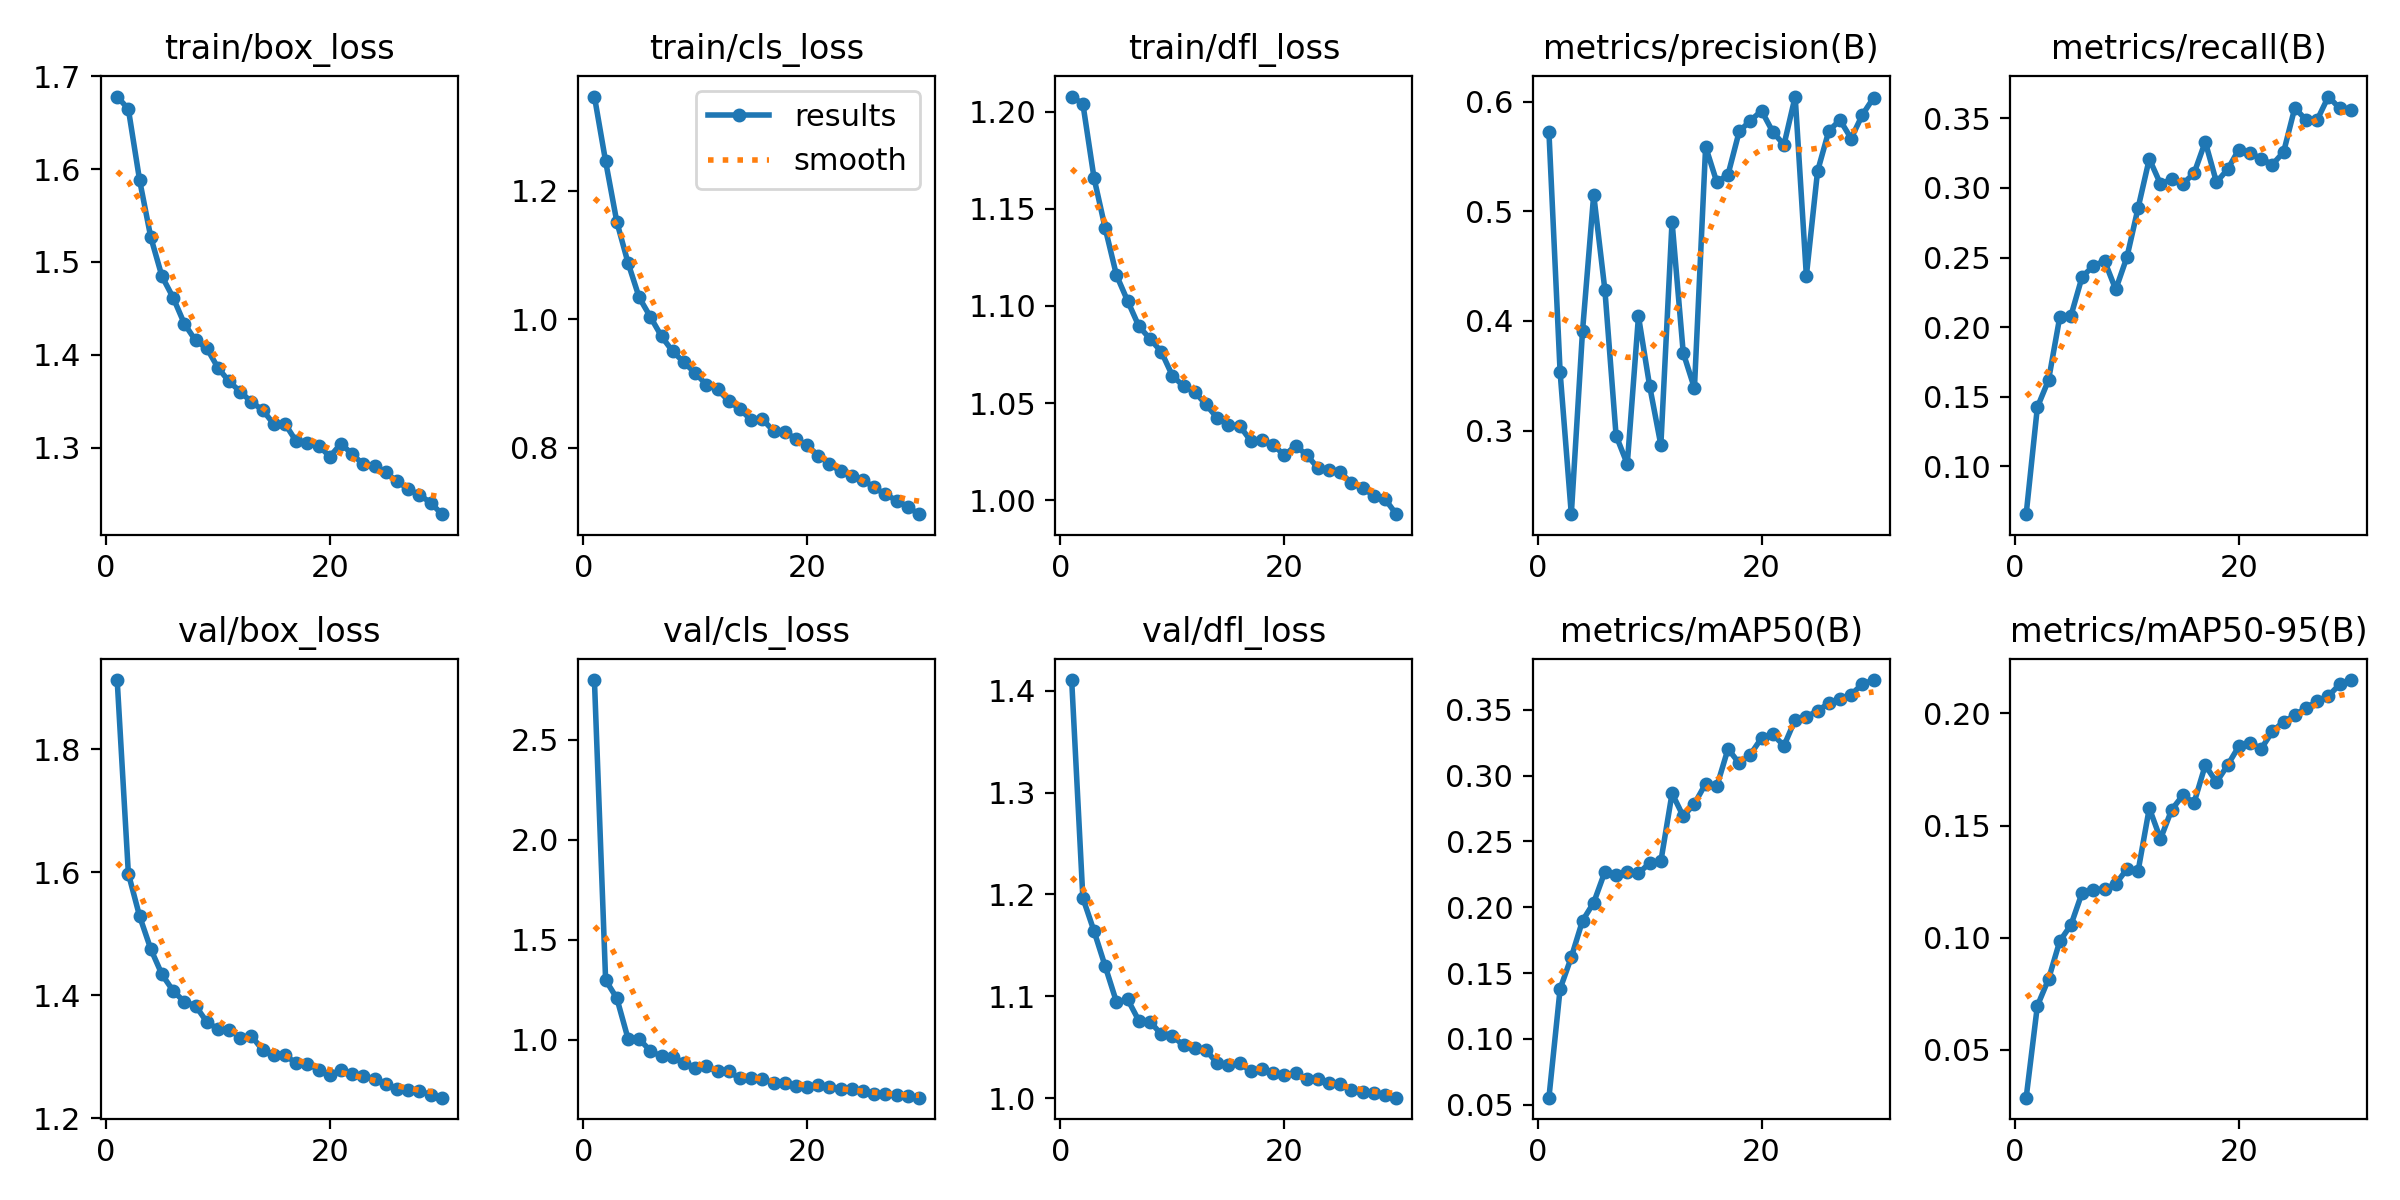


confusion_matrix.png


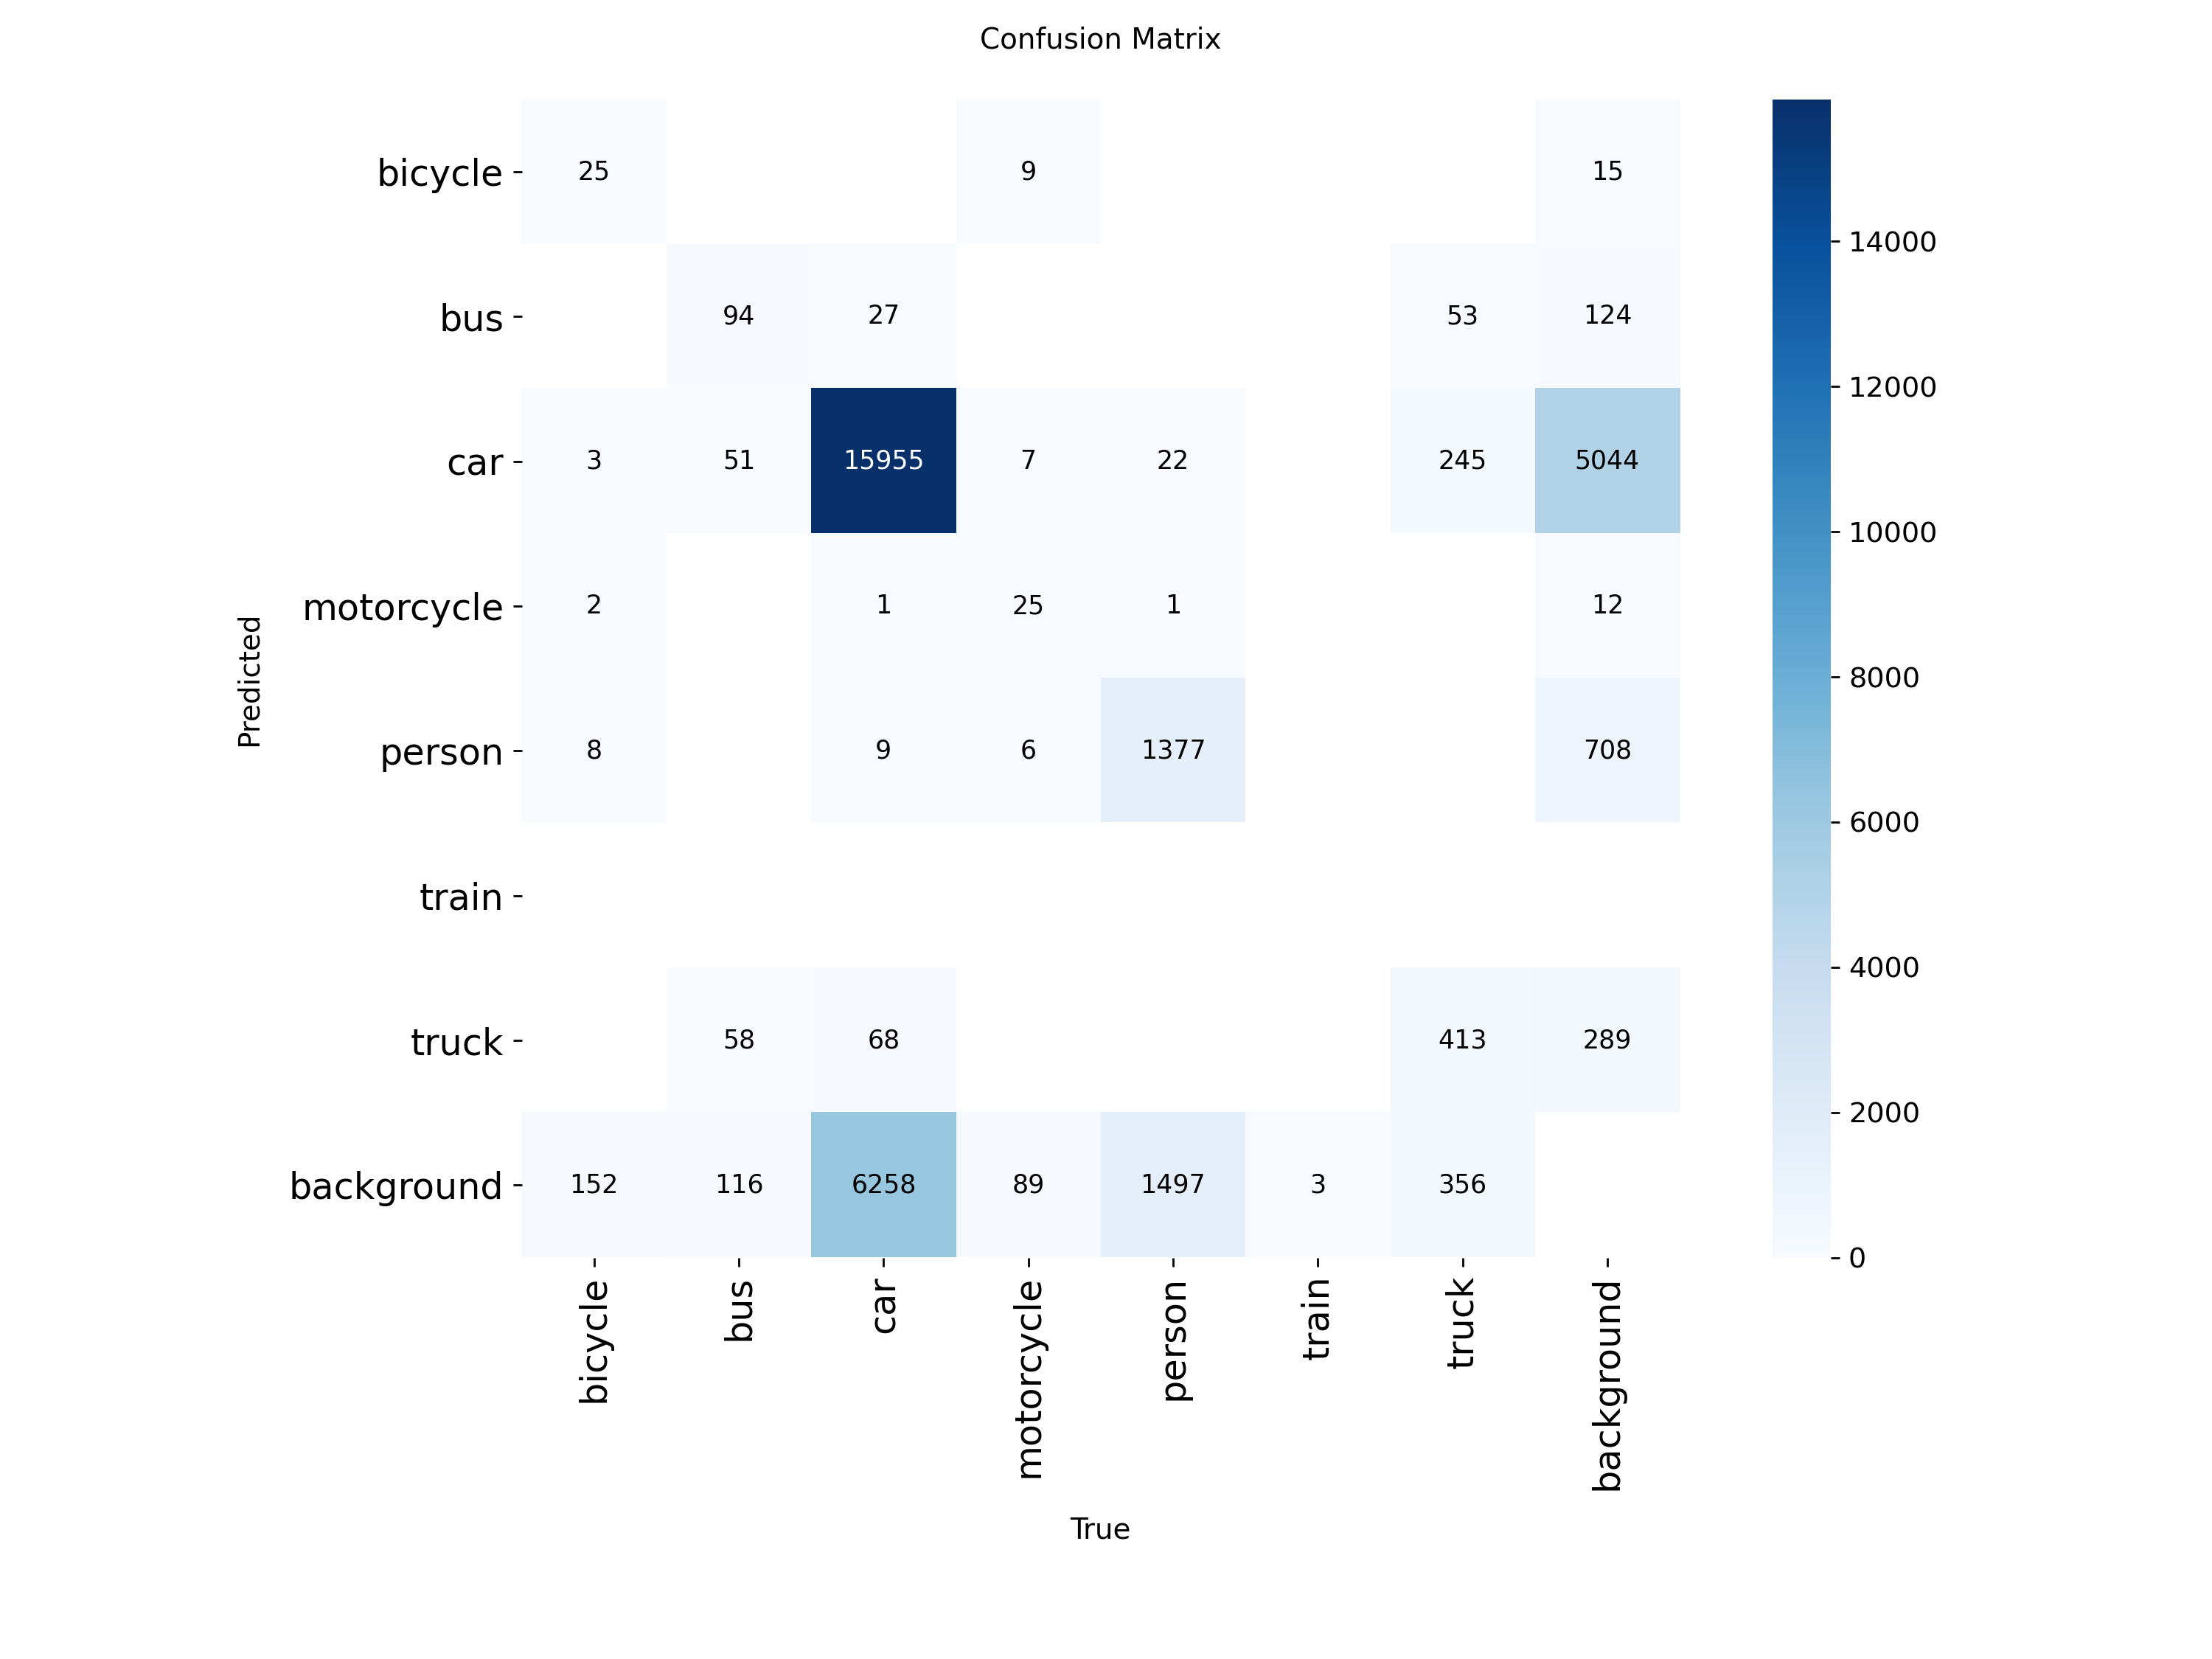

PR_curve.png 파일이 없습니다.
F1_curve.png 파일이 없습니다.
P_curve.png 파일이 없습니다.
R_curve.png 파일이 없습니다.


In [31]:
from pathlib import Path
from IPython.display import Image, display

# 학습 결과 폴더
RUN_DIR = Path("/content/drive/MyDrive/yolo_runs/yolo11s_combined_30epochs_safe")

# 보고 싶은 결과 이미지
result_images = [
    "results.png",
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]

for img_name in result_images:
    img_path = RUN_DIR / img_name

    if img_path.exists():
        print(f"\n{img_name}")
        display(Image(filename=str(img_path), width=900))
    else:
        print(f"{img_name} 파일이 없습니다.")

In [32]:
import pandas as pd
from pathlib import Path

RUN_DIR = Path("/content/drive/MyDrive/yolo_runs/yolo11s_combined_30epochs_safe")
RESULTS_CSV = RUN_DIR / "results.csv"

df = pd.read_csv(RESULTS_CSV)
df.tail()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,5428.78,1.26369,0.73794,1.00883,0.57313,0.34885,0.35495,0.20253,1.24747,0.72981,1.00846,0.00175,0.00175,0.00175
26,27,5632.01,1.25589,0.72711,1.00621,0.58328,0.34889,0.35788,0.20536,1.24639,0.72696,1.00657,0.00142,0.00142,0.00142
27,28,5833.97,1.24907,0.71759,1.00240,0.56635,0.36567,0.36154,0.20774,1.24498,0.72068,1.00494,0.00109,0.00109,0.00109
28,29,6036.42,1.24106,0.70754,1.00059,0.58787,0.35726,0.36947,0.21289,1.23832,0.71580,1.00282,0.00076,0.00076,0.00076
29,30,6238.86,1.22850,0.69632,0.99285,0.60344,0.35634,0.37256,0.21485,1.23372,0.70949,1.00052,0.00043,0.00043,0.00043


In [33]:
from ultralytics import YOLO
from pathlib import Path

BEST_PT = "/content/drive/MyDrive/yolo_runs/yolo11s_combined_30epochs_safe/weights/best.pt"

model = YOLO(BEST_PT)

model.predict(
    source="/content/datasets/DAWN/valid/images",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/drive/MyDrive/yolo_runs",
    name="prediction_examples",
    exist_ok=True
)


image 1/205 /content/datasets/DAWN/valid/images/dusttornado-015_jpg.rf.5QpUvfCnCgCmZslKTWZk.jpg: 384x640 1 bus, 4 cars, 4 persons, 1 truck, 11.8ms
image 2/205 /content/datasets/DAWN/valid/images/dusttornado-018_jpg.rf.G70eioYISEA16m9u48jl.jpg: 416x640 10 cars, 1 person, 16.0ms
image 3/205 /content/datasets/DAWN/valid/images/dusttornado-020_jpg.rf.MJ8xtbLczVNWPjLFCzdl.jpg: 320x640 7 cars, 11.1ms
image 4/205 /content/datasets/DAWN/valid/images/dusttornado-032_jpg.rf.Kh7FxCWmkS8KPW4A0lI1.jpg: 384x640 1 bus, 3 cars, 11.4ms
image 5/205 /content/datasets/DAWN/valid/images/dusttornado-909_jpg.rf.dtAONOvEliMdgENg4Okg.jpg: 480x640 39 cars, 4 trucks, 13.0ms
image 6/205 /content/datasets/DAWN/valid/images/foggy-002_jpg.rf.JLun85cvllwtrbzjCUHG.jpg: 480x640 1 car, 1 motorcycle, 3 persons, 12.3ms
image 7/205 /content/datasets/DAWN/valid/images/foggy-003_jpg.rf.aro26PW5hS5vLrOJfEFE.jpg: 352x640 4 cars, 11.4ms
image 8/205 /content/datasets/DAWN/valid/images/foggy-006_jpg.rf.K6lfdQ41orzZFcEPZIbt.jpg: 

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'bicycle', 1: 'bus', 2: 'car', 3: 'motorcycle', 4: 'person', 5: 'train', 6: 'truck'}
 obb: None
 orig_img: array([[[226, 232, 231],
         [227, 233, 232],
         [228, 233, 232],
         ...,
         [227, 233, 232],
         [226, 232, 231],
         [226, 232, 231]],
 
        [[227, 233, 232],
         [227, 233, 232],
         [227, 233, 232],
         ...,
         [226, 232, 231],
         [224, 230, 229],
         [226, 232, 231]],
 
        [[227, 233, 232],
         [224, 230, 229],
         [227, 233, 232],
         ...,
         [225, 231, 230],
         [226, 232, 231],
         [225, 231, 230]],
 
        ...,
 
        [[160, 165, 163],
         [159, 164, 162],
         [158, 164, 163],
         ...,
         [158, 165, 162],
         [161, 166, 164],
         [159, 164, 162]],
 
        [[160, 167, 164],
         

테스트 결과 이미지 갯수: 205
dusttornado-015_jpg.rf.5QpUvfCnCgCmZslKTWZk.jpg


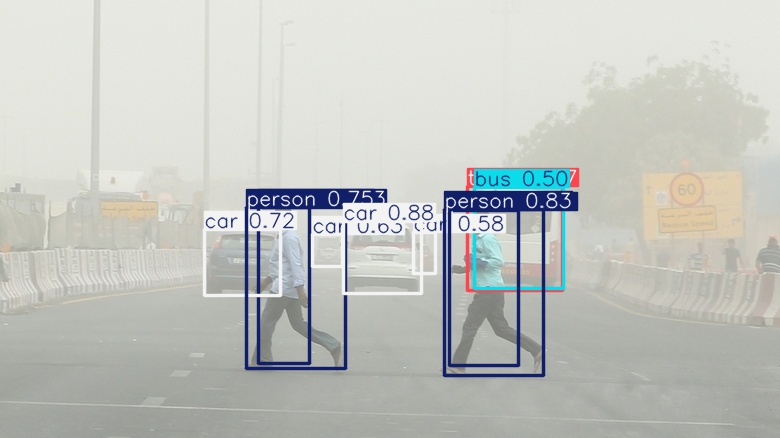

dusttornado-018_jpg.rf.G70eioYISEA16m9u48jl.jpg


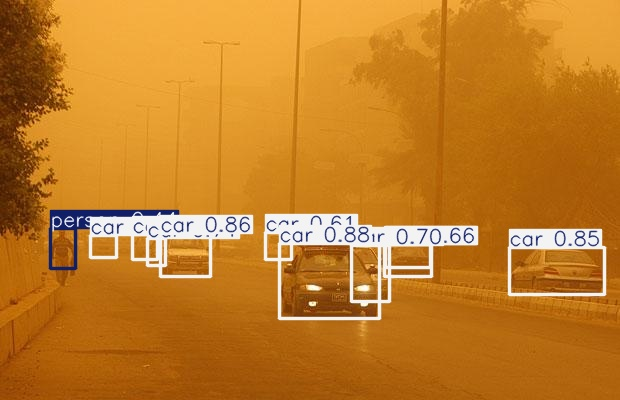

dusttornado-020_jpg.rf.MJ8xtbLczVNWPjLFCzdl.jpg


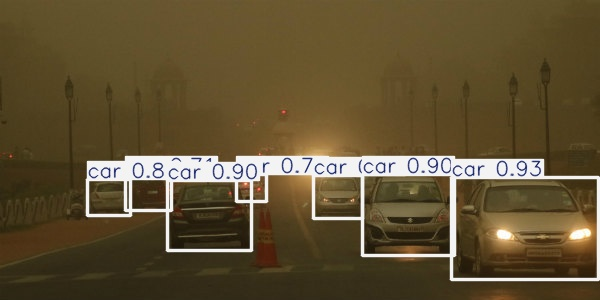

dusttornado-032_jpg.rf.Kh7FxCWmkS8KPW4A0lI1.jpg


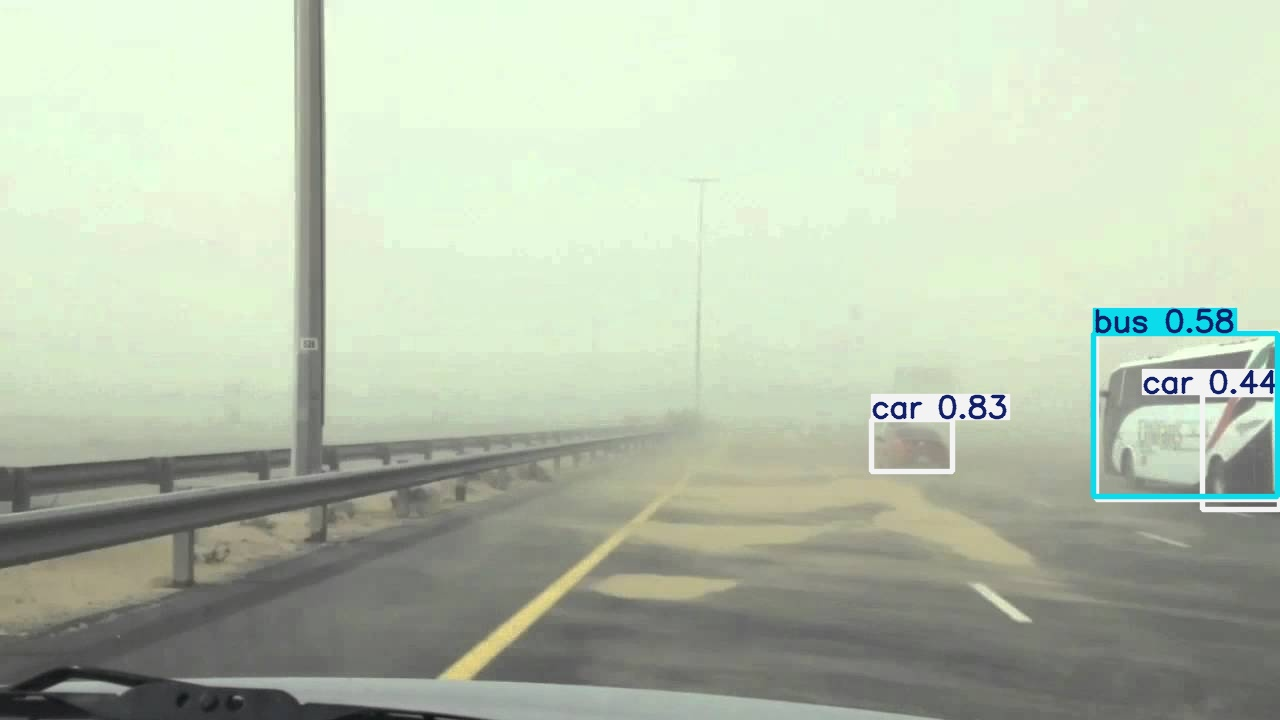

dusttornado-909_jpg.rf.dtAONOvEliMdgENg4Okg.jpg


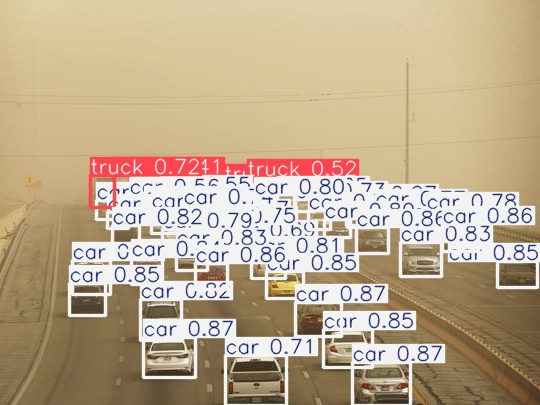

foggy-002_jpg.rf.JLun85cvllwtrbzjCUHG.jpg


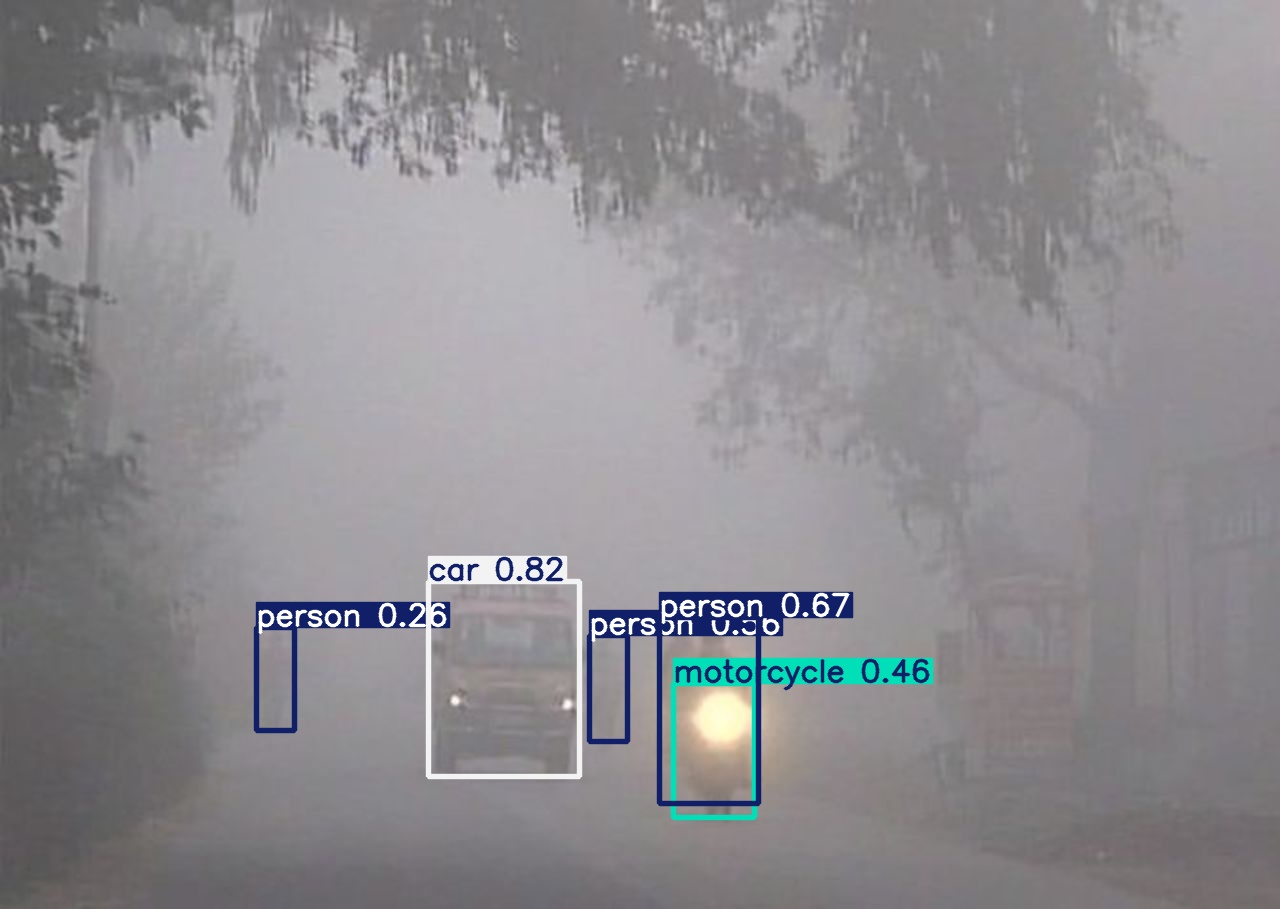

foggy-003_jpg.rf.aro26PW5hS5vLrOJfEFE.jpg


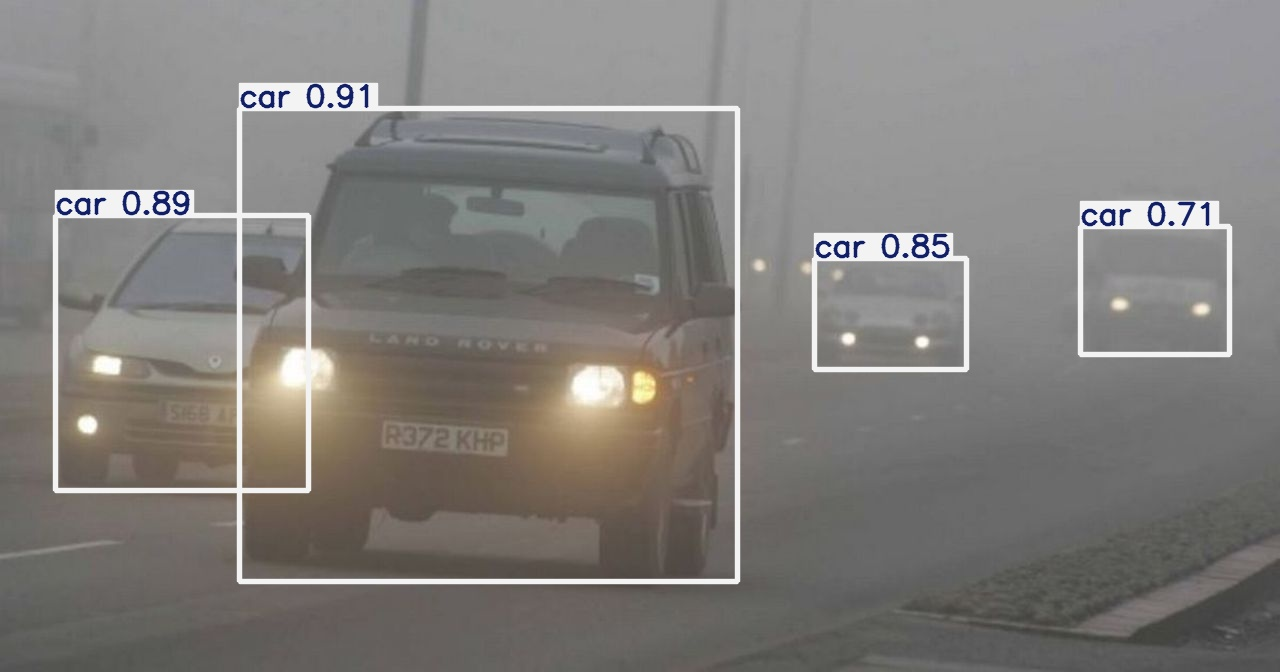

foggy-006_jpg.rf.K6lfdQ41orzZFcEPZIbt.jpg


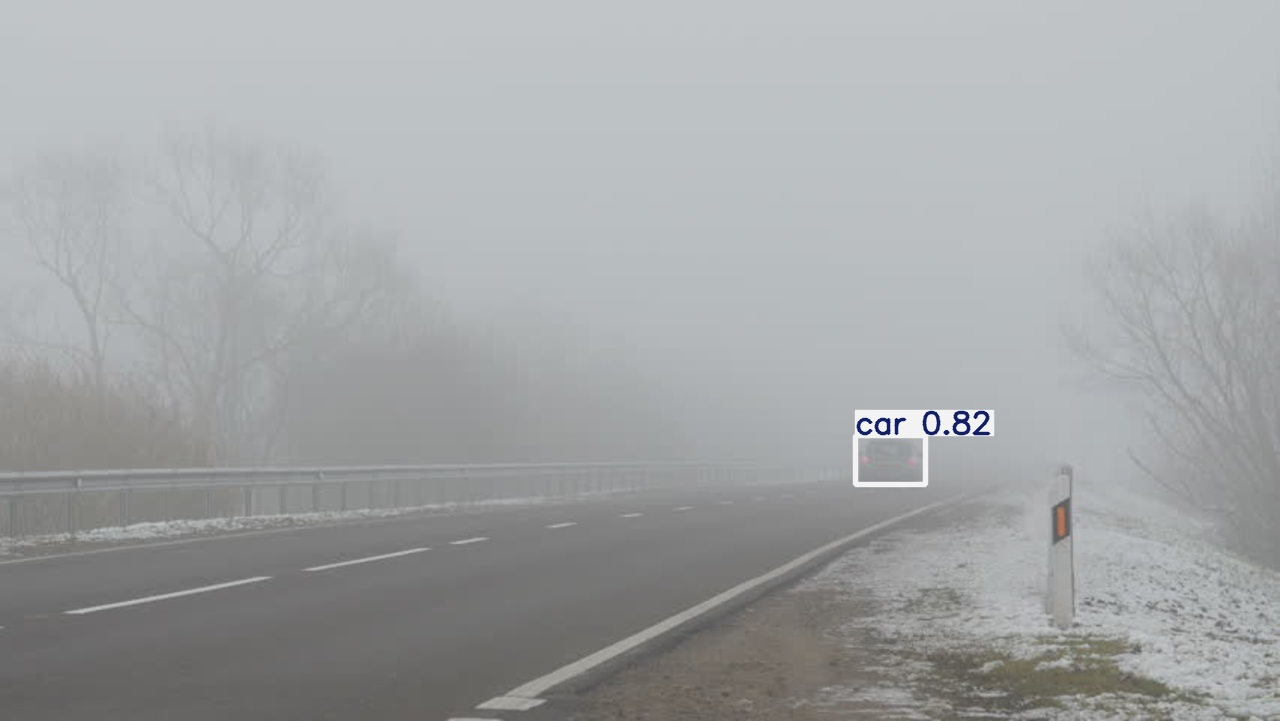

foggy-016_jpg.rf.XYDdUyZGymRv2DCxKGbF.jpg


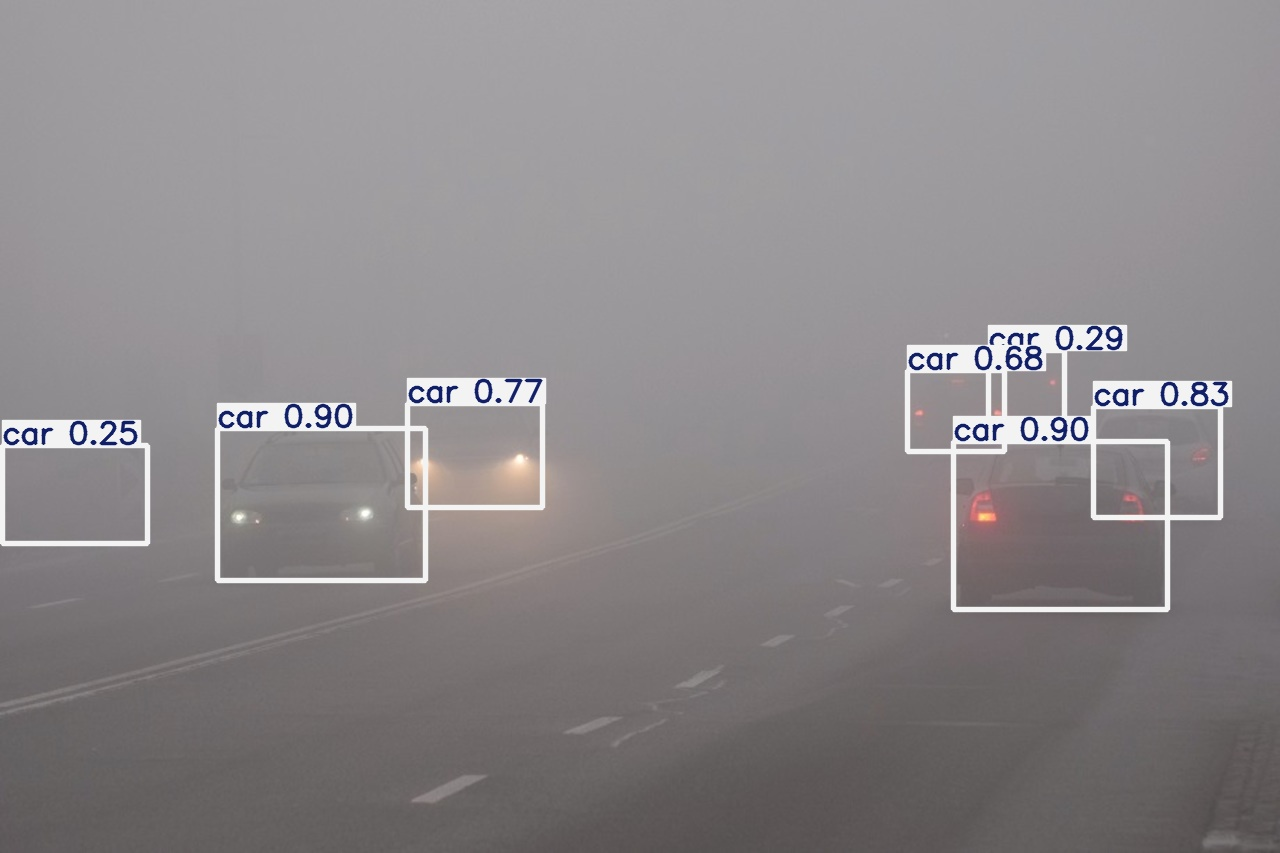

foggy-020_jpg.rf.1BtXBaQCU6IJnjsbqlm7.jpg


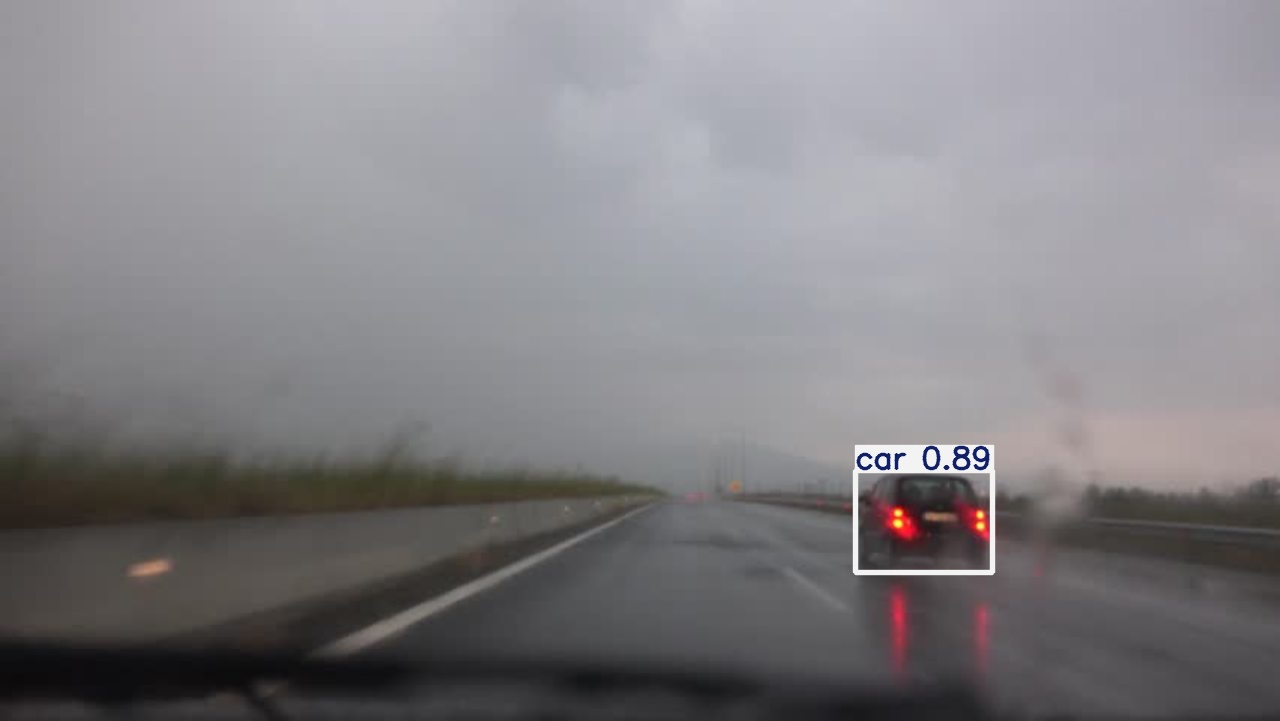

foggy-023_jpg.rf.BGzToFxACo6kNs81RYC3.jpg


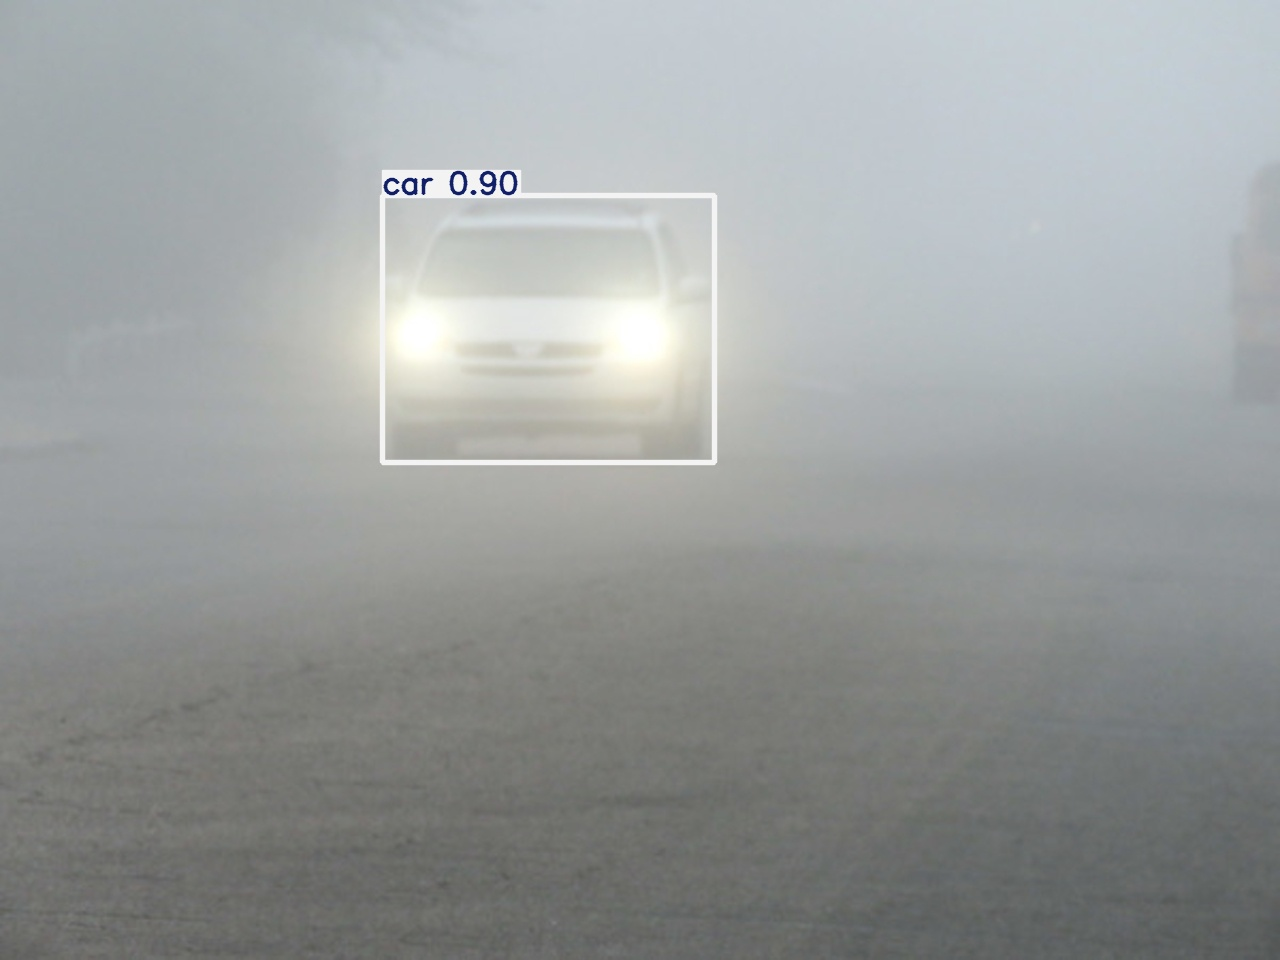

foggy-025_jpg.rf.u6vyVdwFE26XzspespYC.jpg


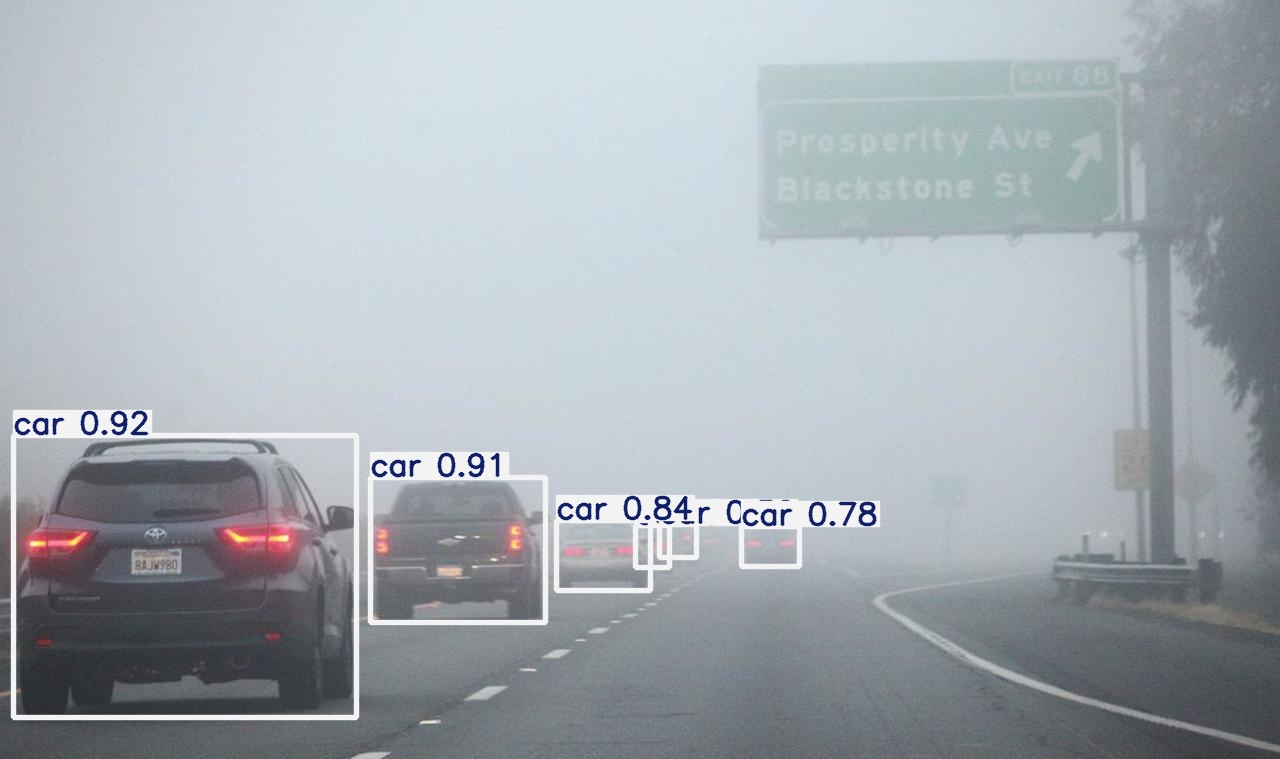

foggy-044_jpg.rf.XmTQ0nxBLdMvl5rs5LRl.jpg


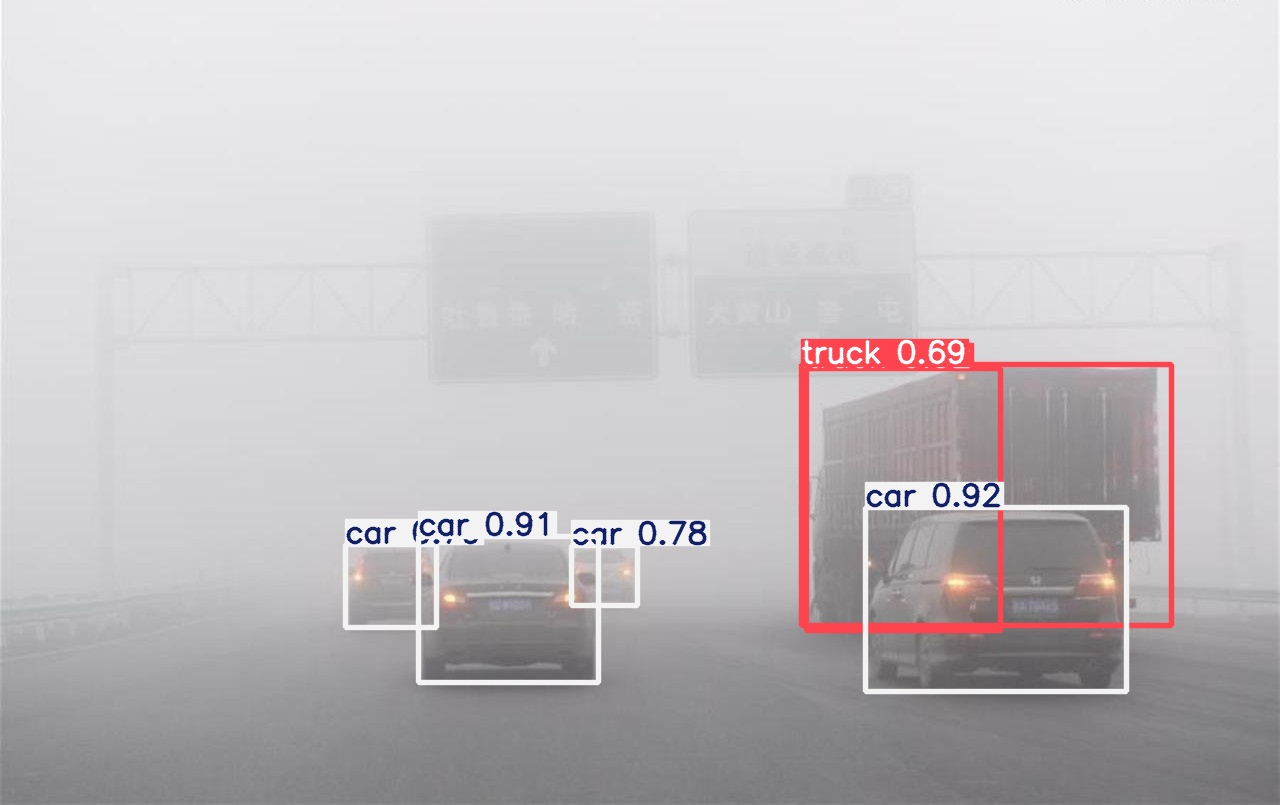

foggy-045_jpg.rf.V4F5uHEB6pJ5tWLK1QH2.jpg


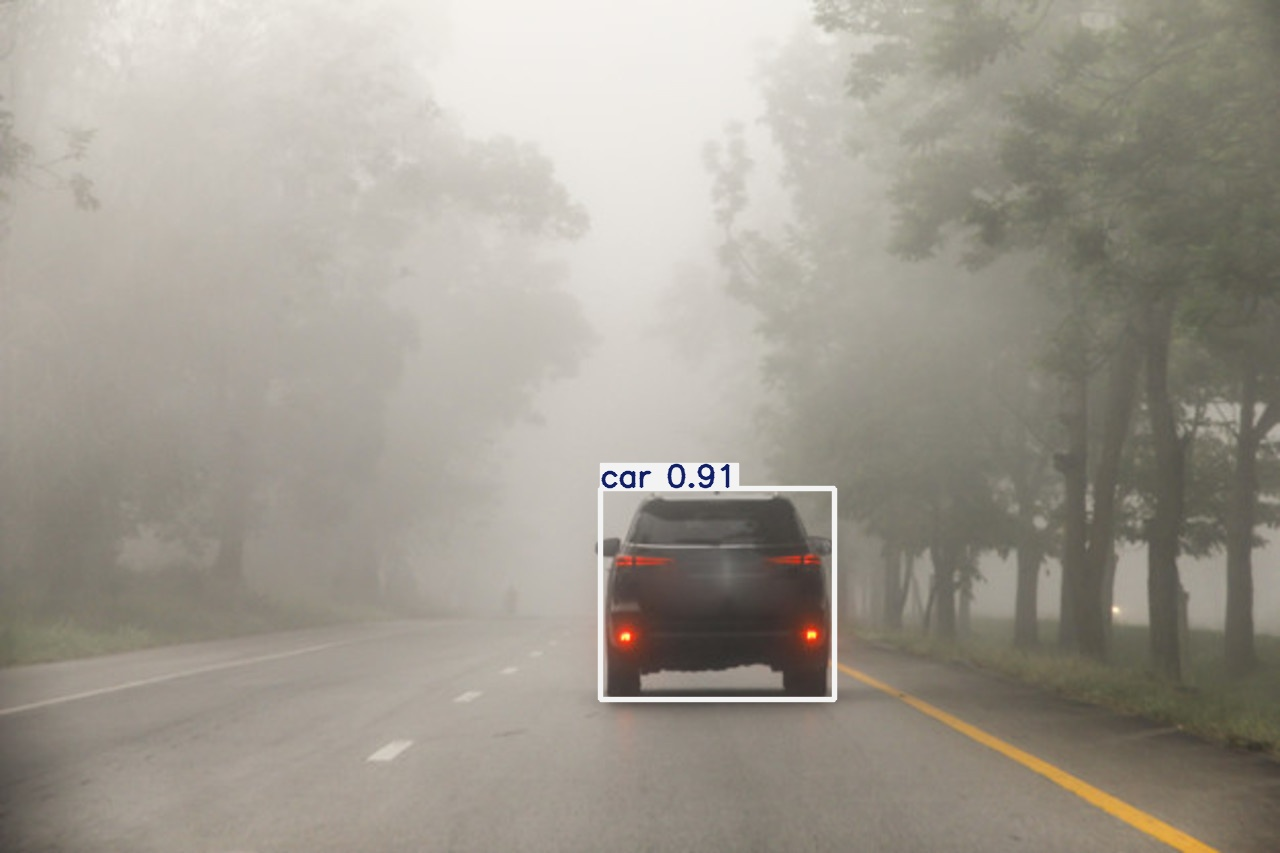

foggy-047_jpg.rf.7pe9LR1mhC5TEEwICU2C.jpg


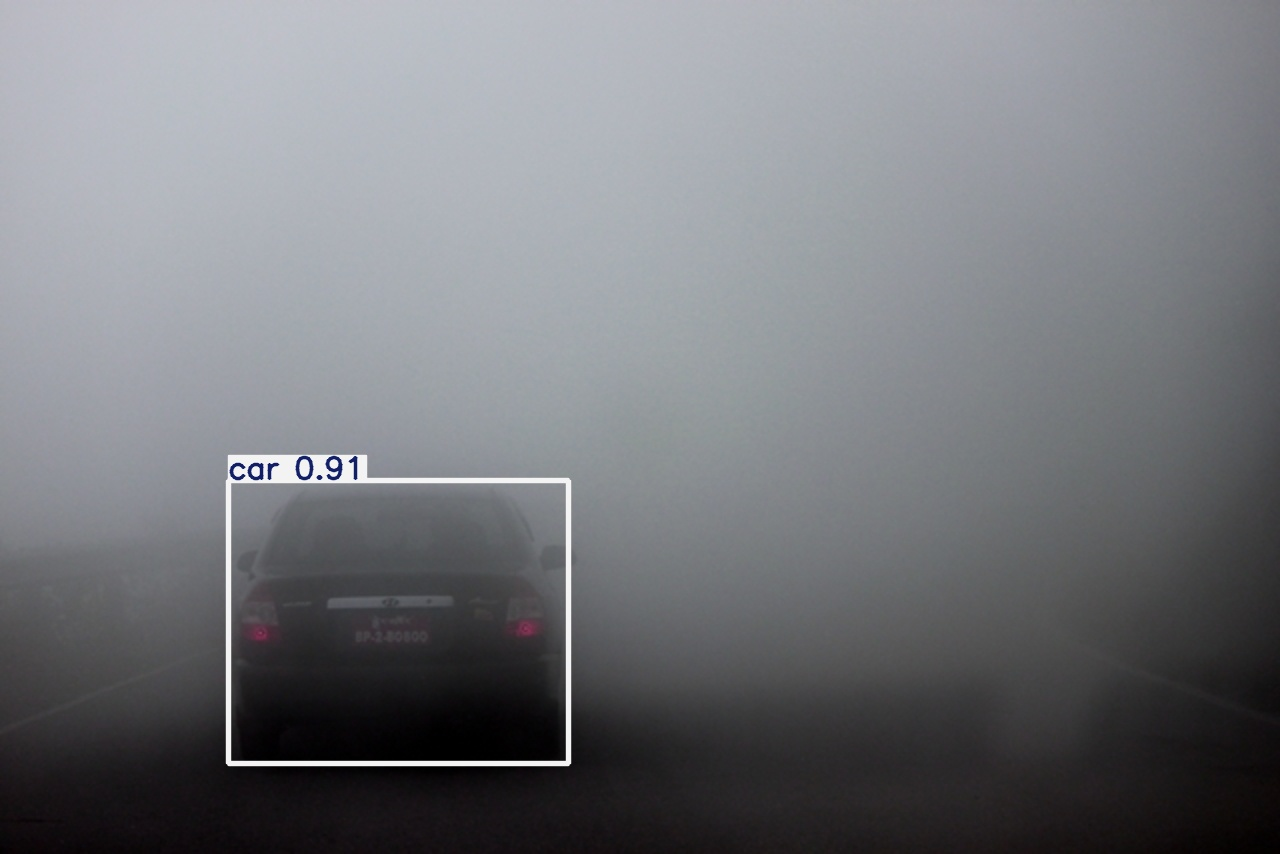

foggy-048_jpg.rf.9HOAzmhsqwsPXsZ1HKaA.jpg


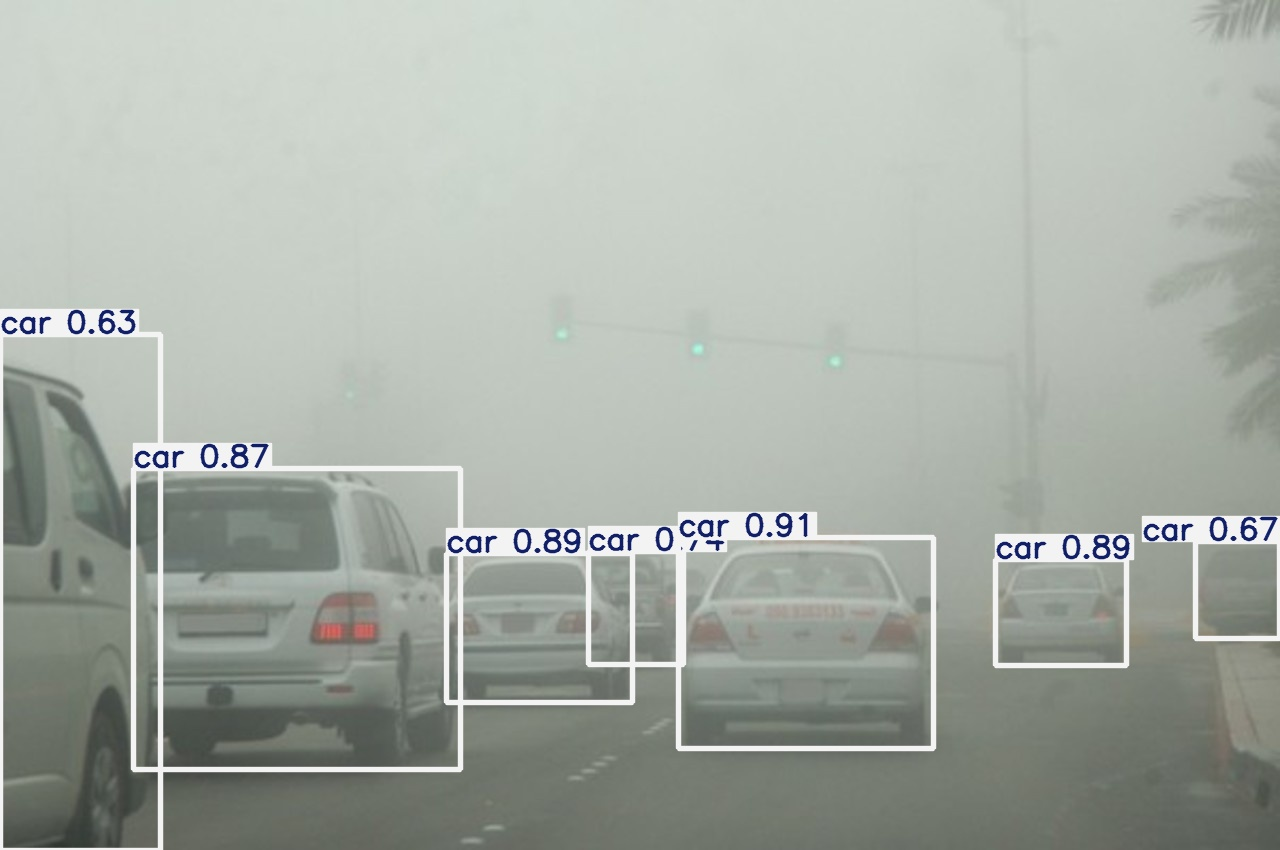

foggy-055_jpg.rf.LxF4FtrZP02UytrPgwZM.jpg


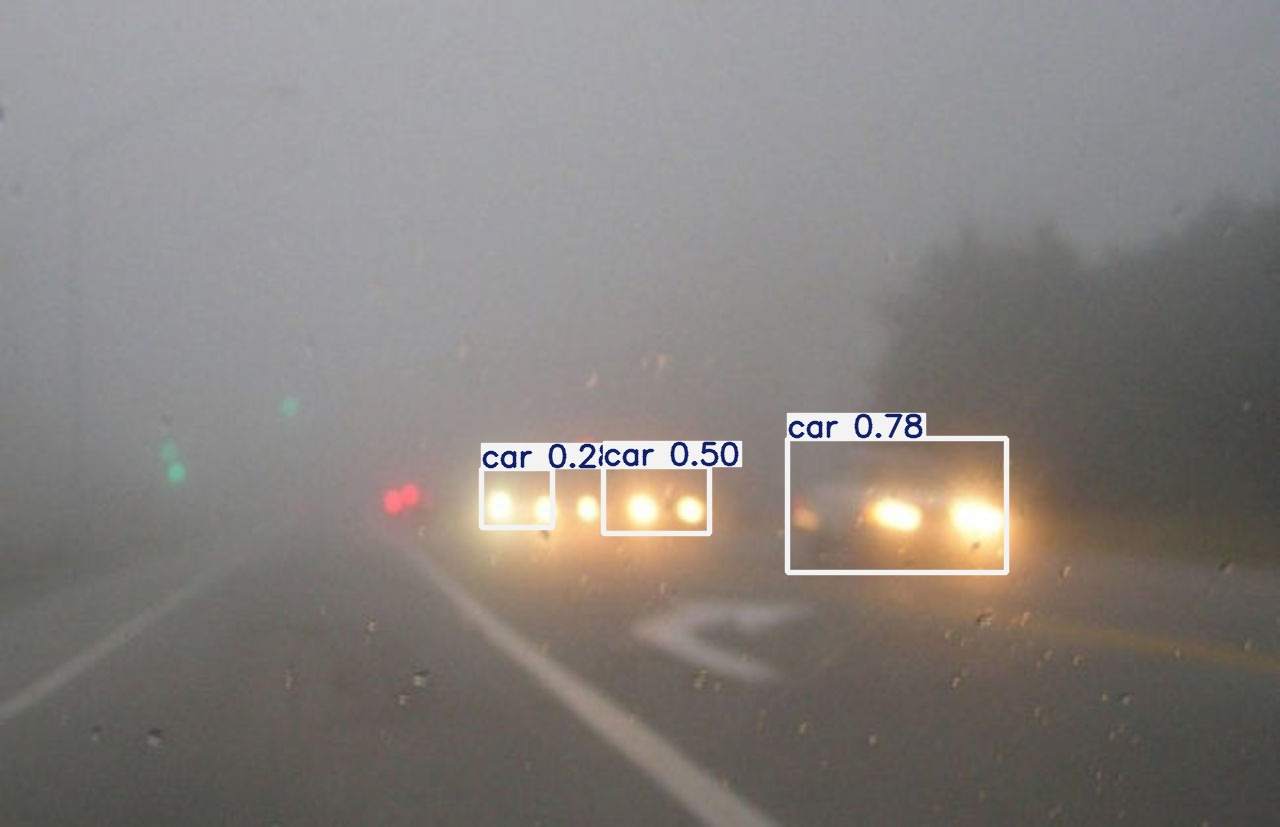

foggy-065_jpg.rf.HogXxAIkZC3xoxr6WXfW.jpg


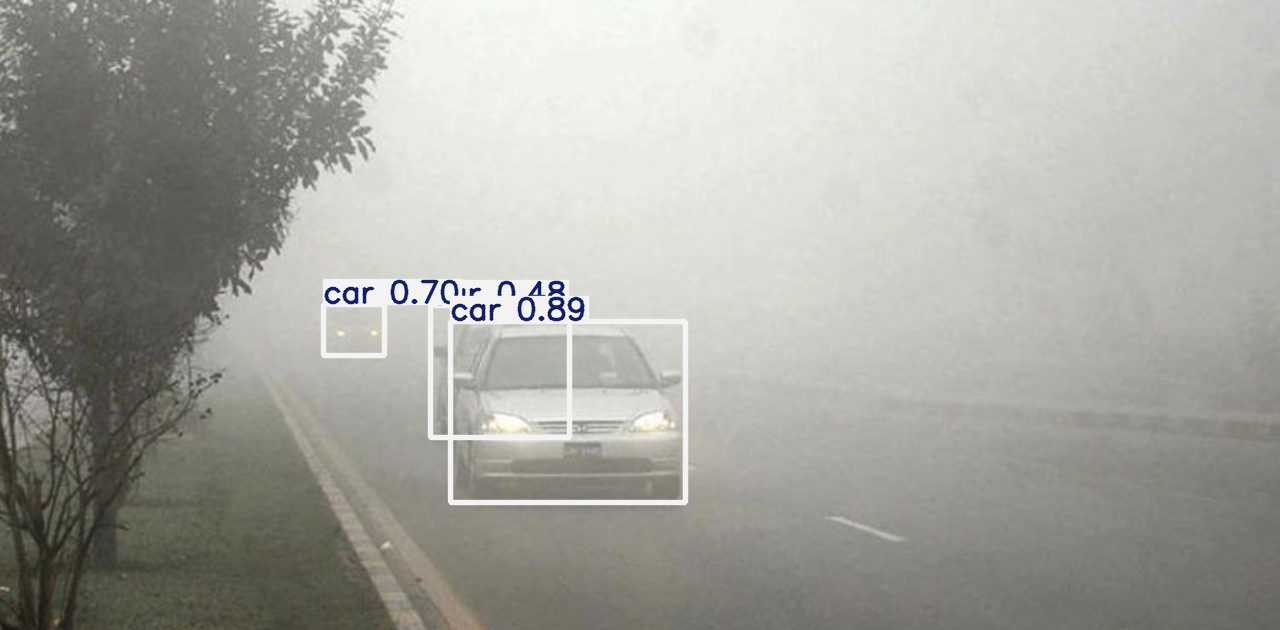

foggy-067_jpg.rf.Mh61sodXZKpe0KL3Aw0E.jpg


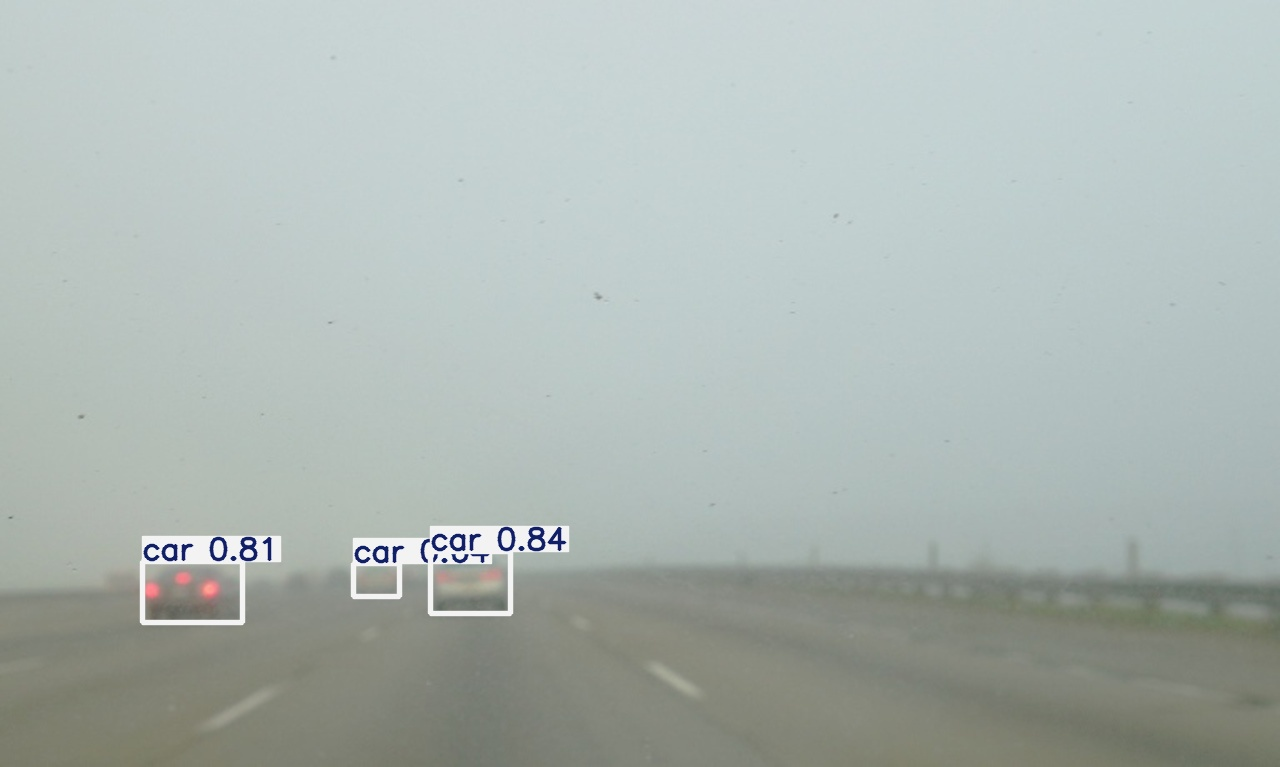

foggy-072_jpg.rf.jS8hu9wV0MAR3waOHTjL.jpg


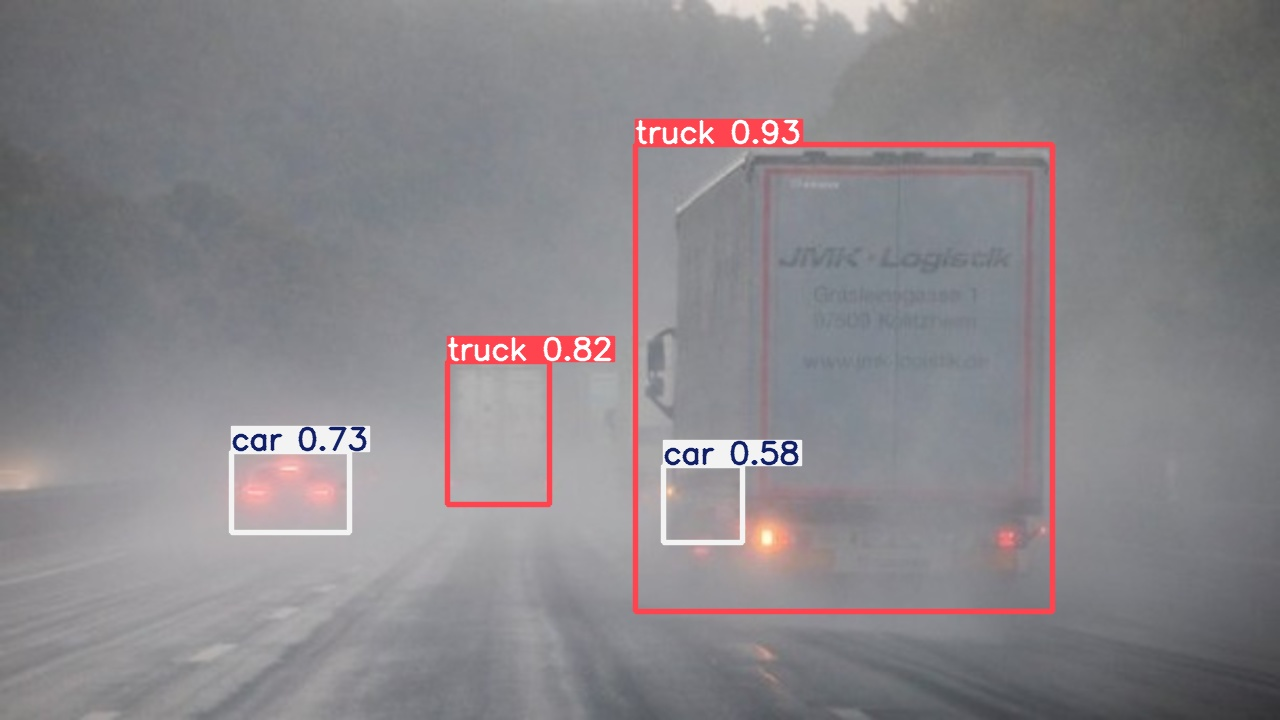

foggy-086_jpg.rf.rgA4EFxchgwVL83f739g.jpg


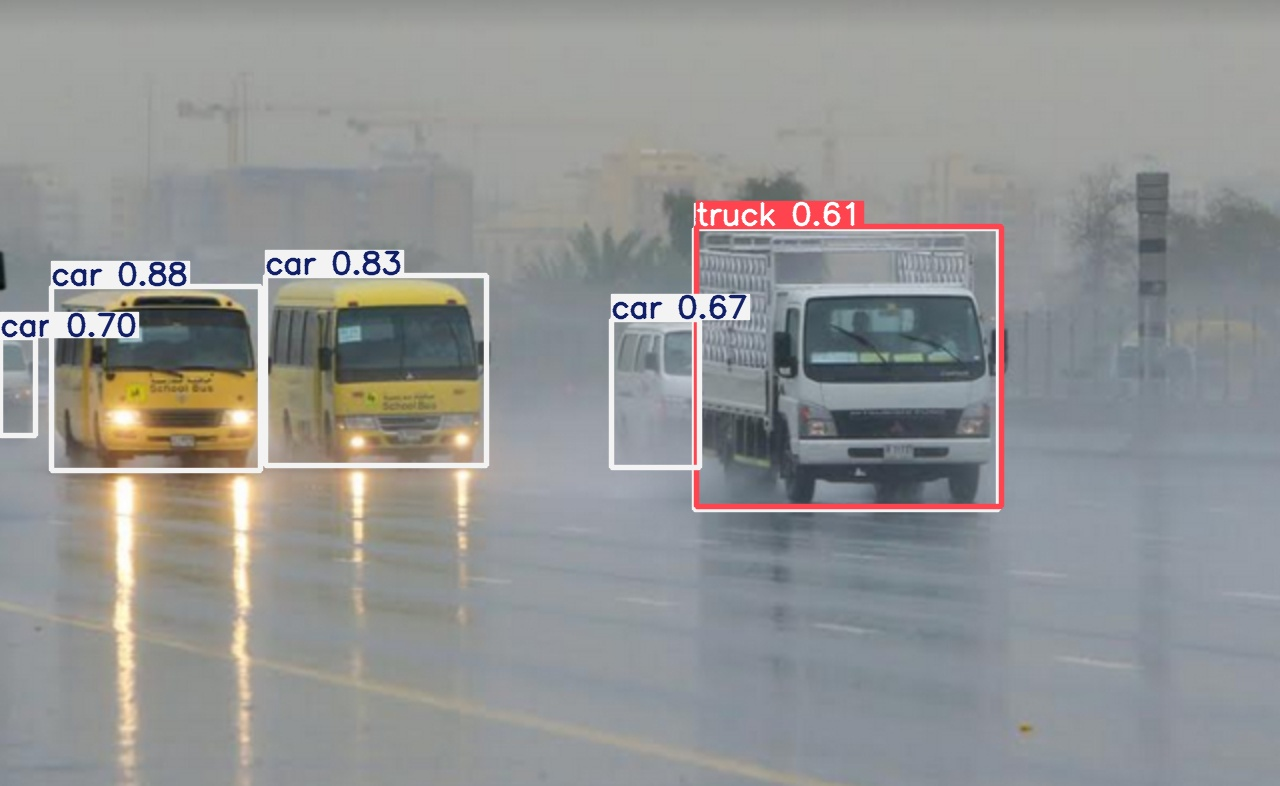

foggy-100_jpg.rf.ACT2FA8Qf4QnLm8VlLO0.jpg


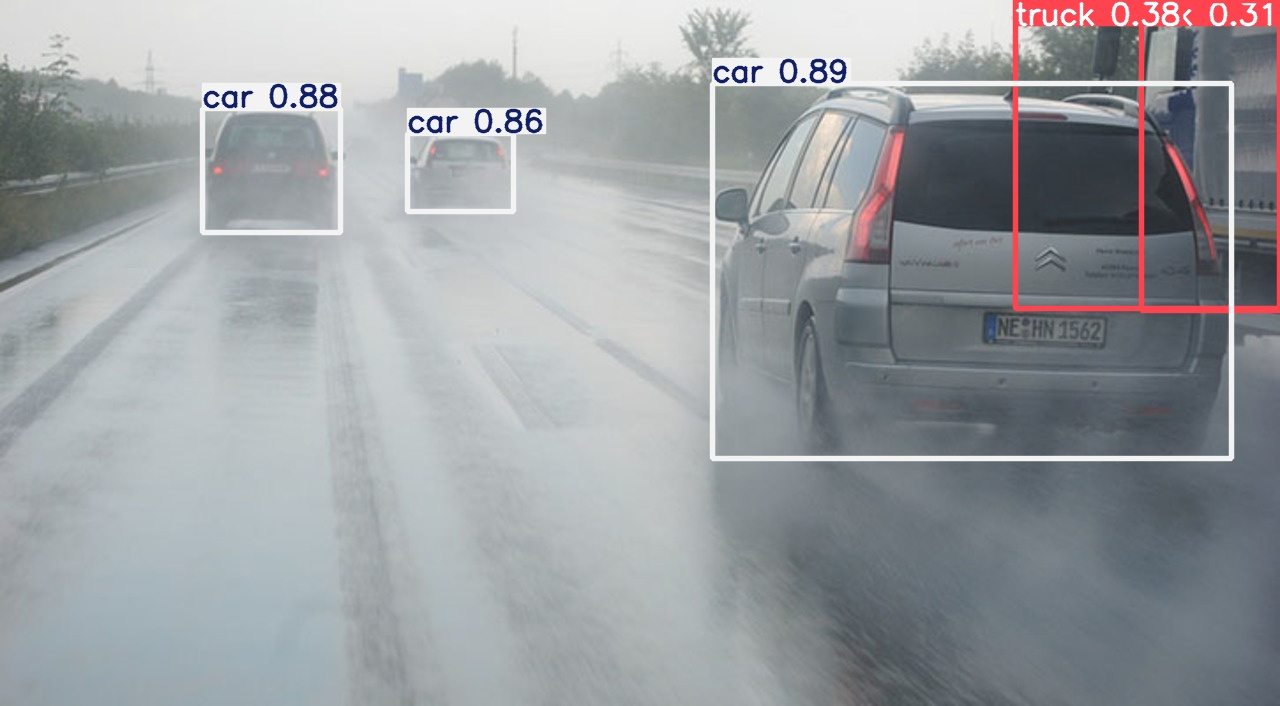

foggy-108_jpg.rf.vQcnmOK8OoLyjWzCThkZ.jpg


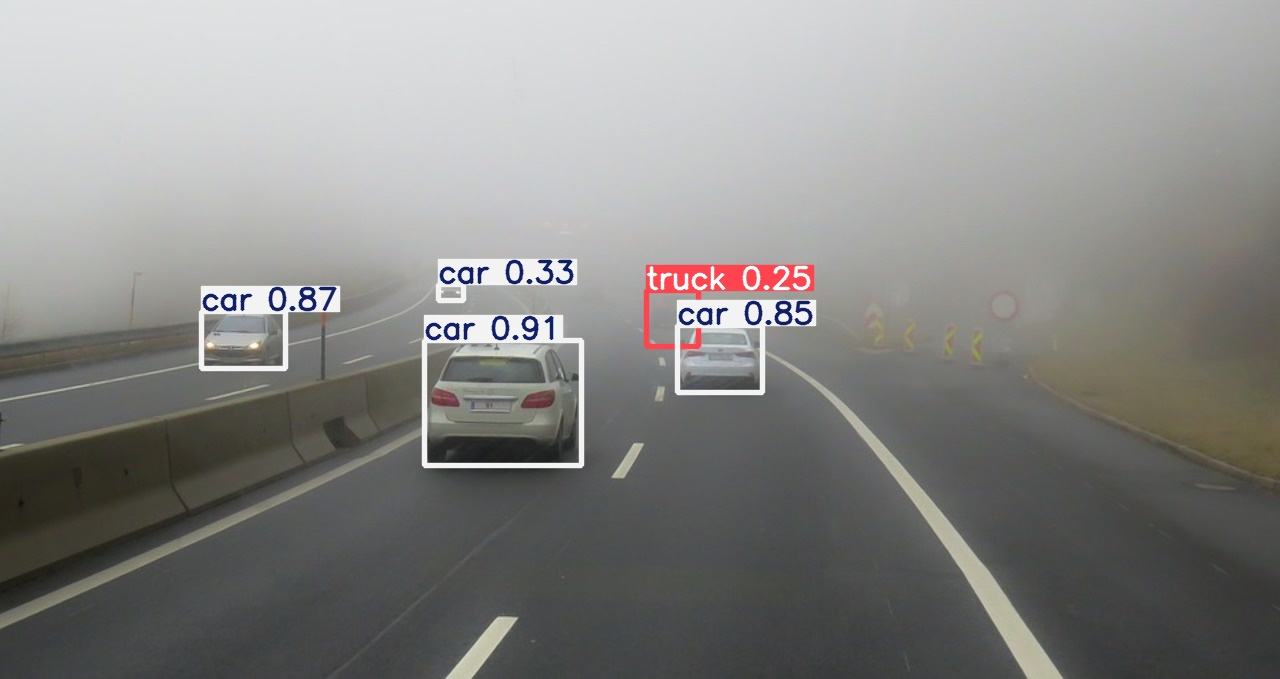

foggy-109_jpg.rf.bdGEKsBW8svJKB3hdj0f.jpg


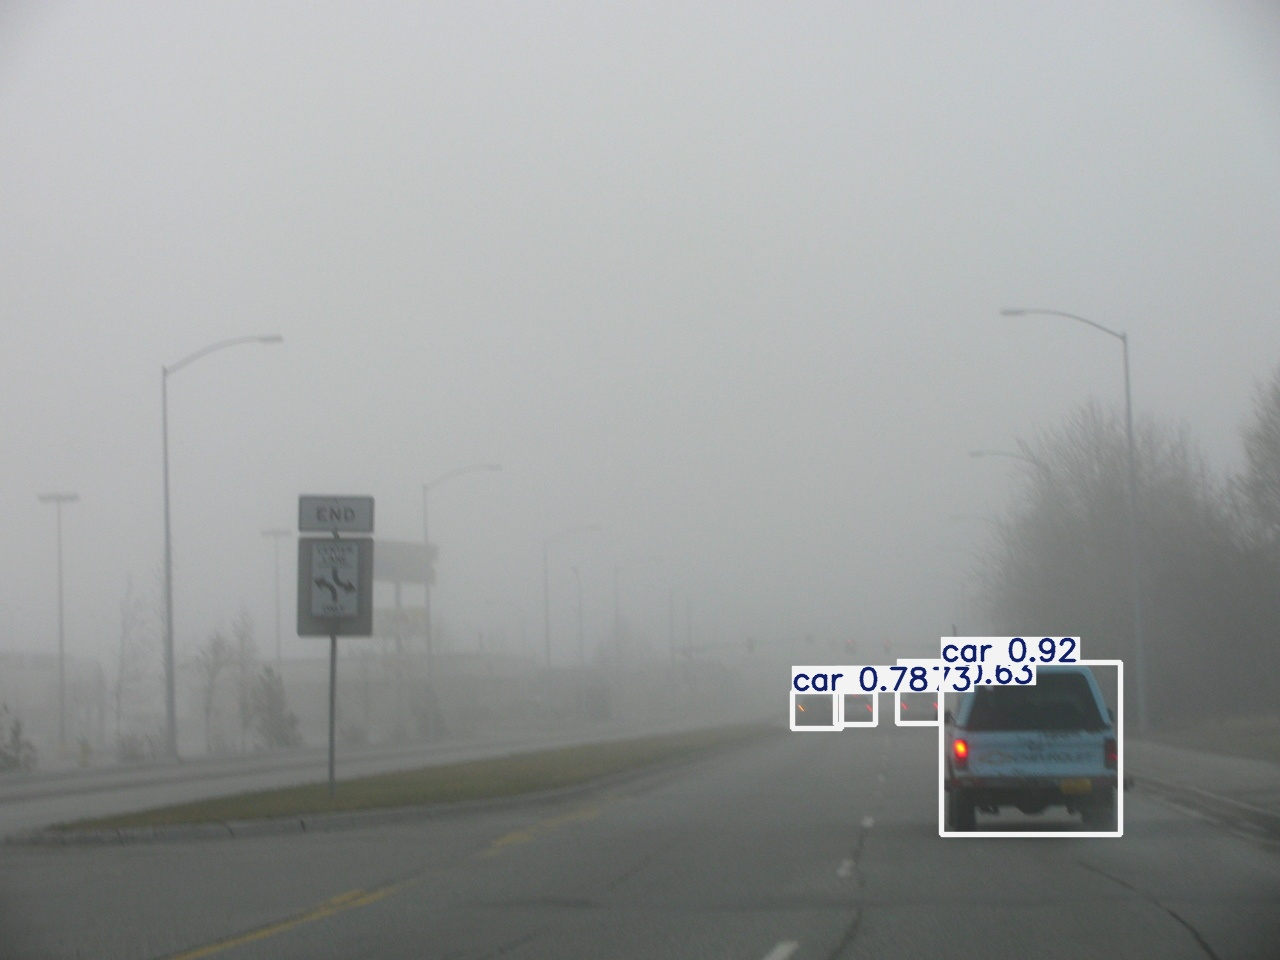

haze-005_jpg.rf.fV1yzoxSg7YCoo4t9oJV.jpg


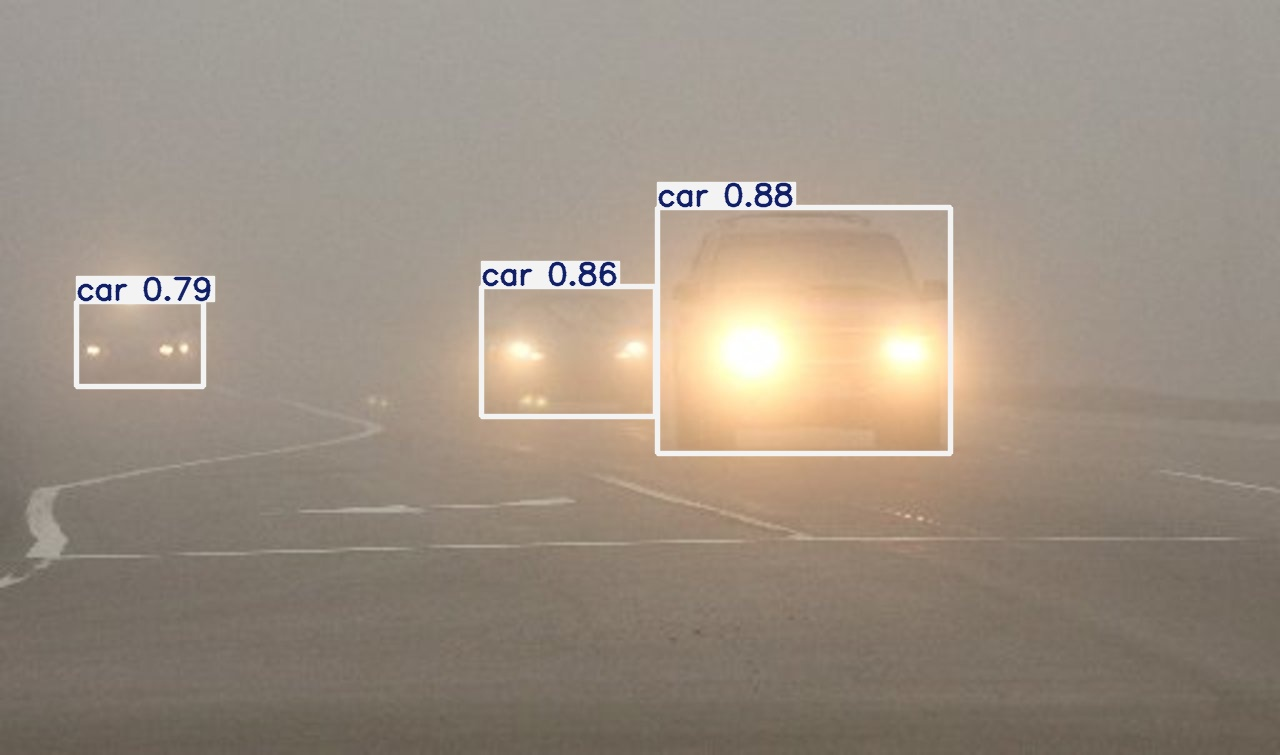

haze-011_jpg.rf.L4ZqUETB1I5KHnlcWdSw.jpg


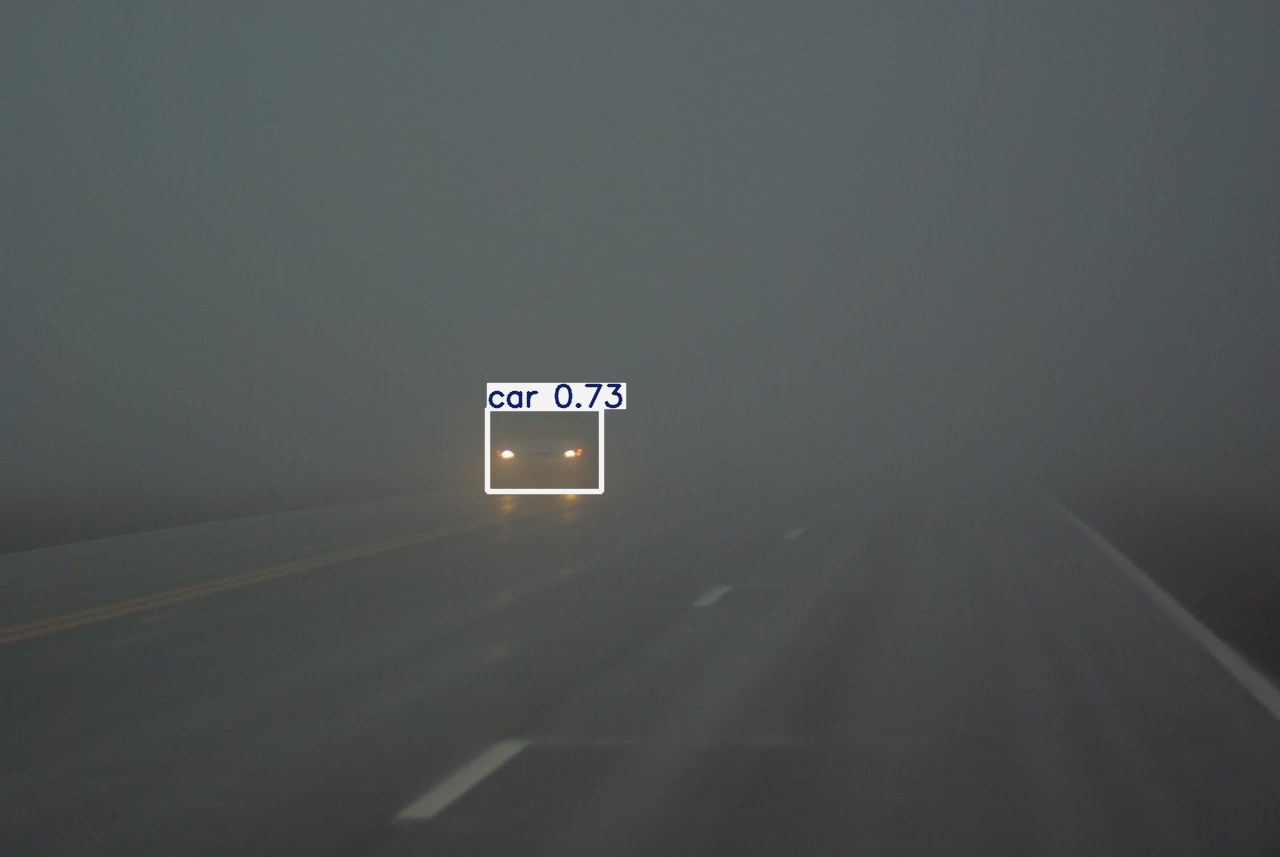

haze-018_jpg.rf.xIGcXmr8E9i8SFocexAo.jpg


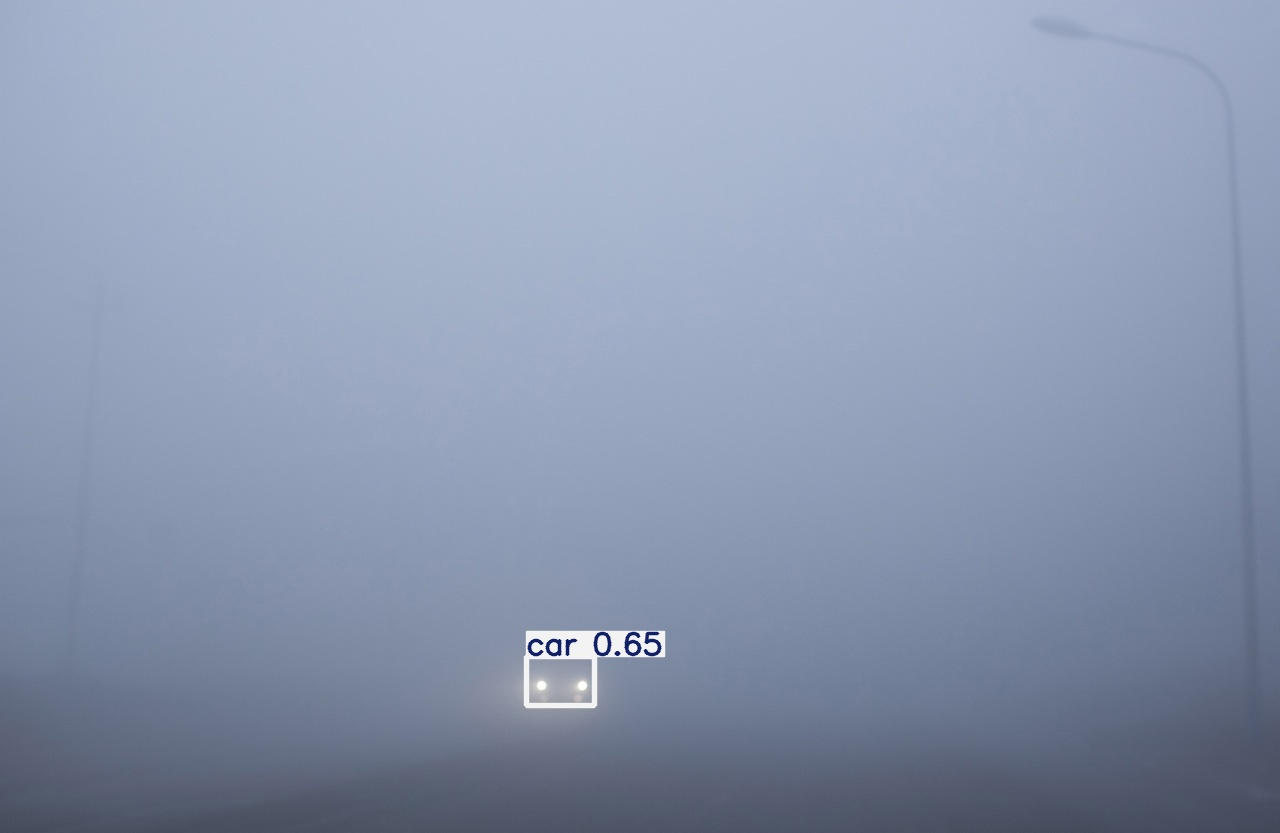

haze-020_jpg.rf.RrEYQe8mDQsWvDjYb7s4.jpg


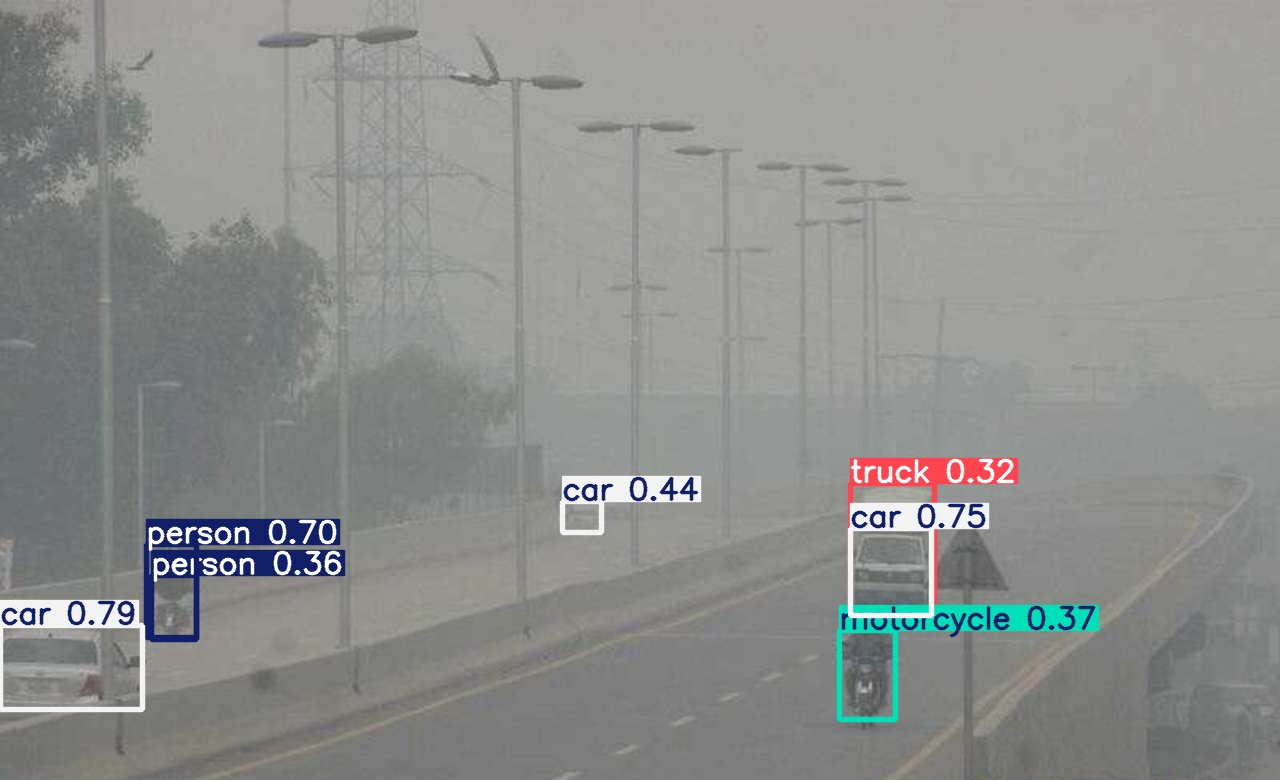

haze-021_jpg.rf.quHuQQbduXPQWHhuIlkP.jpg


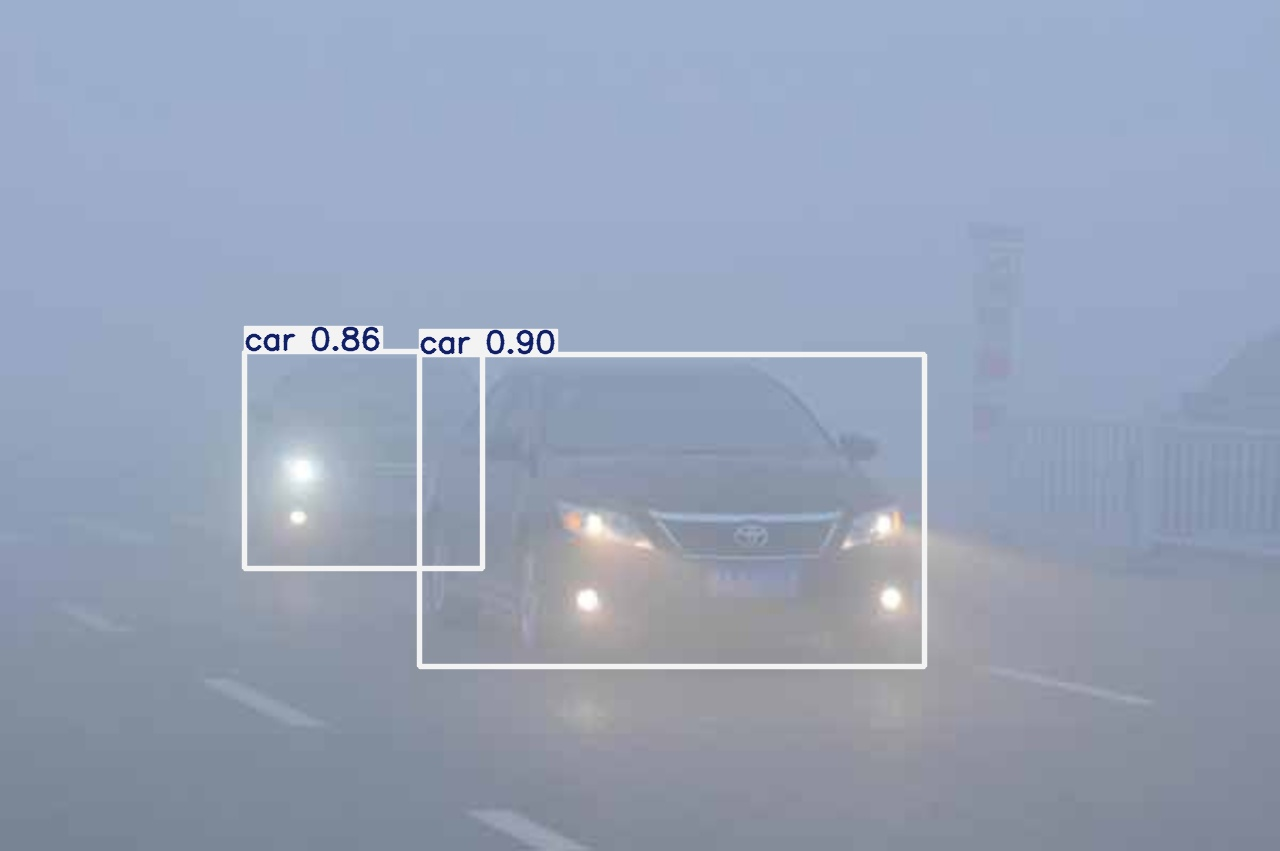

haze-030_jpg.rf.3tt97CGtB4hkhBOLeu6Z.jpg


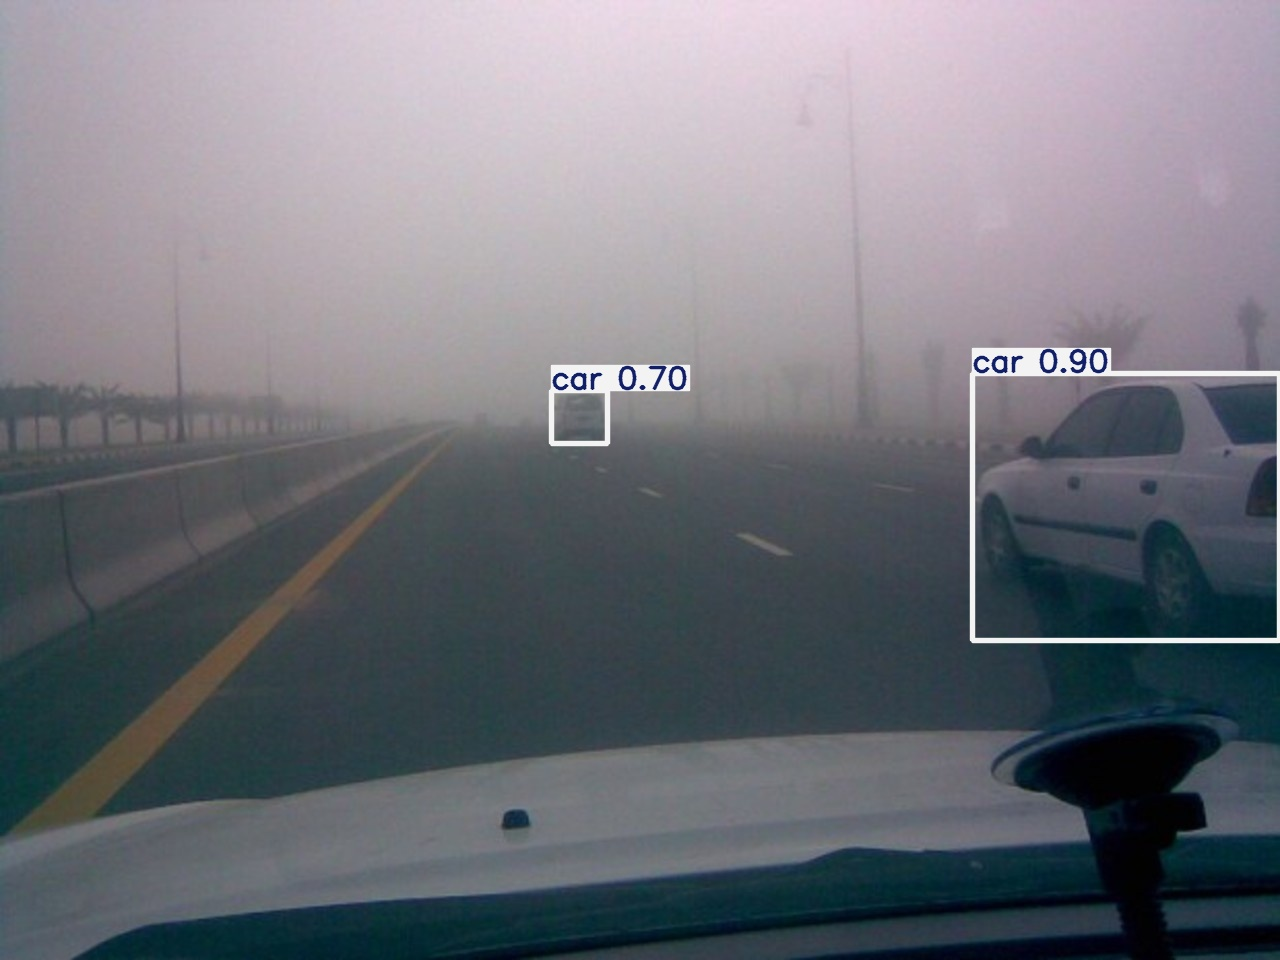

In [38]:
from pathlib import Path
from IPython.display import Image, display

# 예측 결과 이미지 폴더
PRED_DIR = Path("/content/drive/MyDrive/yolo_runs/prediction_examples")

# jpg, png 이미지 불러오기
pred_images = list(PRED_DIR.glob("*.jpg")) + list(PRED_DIR.glob("*.png"))

# 파일 이름 기준으로 정렬
pred_images = sorted(pred_images)

print("테스트 결과 이미지 갯수:", len(pred_images))

# 보고 싶은 이미지 개수 설정
SHOW_NUM = 30

for img_path in pred_images[:SHOW_NUM]:
    print(img_path.name)
    display(Image(filename=str(img_path), width=800))

In [30]:
!ls -lh /content/drive/MyDrive/yolo_runs

total 8.0K
drwx------ 2 root root 4.0K Jun  7 17:41 prediction_examples
drwx------ 3 root root 4.0K Jun  7 17:40 yolo11s_combined_30epochs_safe


In [39]:
from pathlib import Path
import shutil
import textwrap
import os

# 최종 제출 폴더
SUBMIT_DIR = Path("/content/drive/MyDrive/VisionaryAI_YOLO_Final_Project")
CODE_DIR = SUBMIT_DIR / "01_code"
DATASET_DIR = SUBMIT_DIR / "02_dataset"
MODEL_DIR = SUBMIT_DIR / "03_model"
RESULT_DIR = SUBMIT_DIR / "04_results"
PRED_DIR = RESULT_DIR / "prediction_examples"

# 기존 제출 폴더가 있으면 삭제 후 새로 생성
if SUBMIT_DIR.exists():
    shutil.rmtree(SUBMIT_DIR)

for d in [CODE_DIR, DATASET_DIR, MODEL_DIR, RESULT_DIR, PRED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 학습 결과 폴더
RUN_DIR = Path("/content/drive/MyDrive/yolo_runs/yolo11s_combined_30epochs_safe")
WEIGHTS_DIR = RUN_DIR / "weights"

# 1. 모델 파일 복사
for file_name in ["best.pt", "last.pt"]:
    src = WEIGHTS_DIR / file_name
    if src.exists():
        shutil.copy2(src, MODEL_DIR / file_name)
        print("모델 복사 완료:", file_name)
    else:
        print("모델 파일 없음:", src)

# 2. 결과 파일 복사
result_files = [
    "results.csv",
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]

for file_name in result_files:
    src = RUN_DIR / file_name
    if src.exists():
        shutil.copy2(src, RESULT_DIR / file_name)
        print("결과 파일 복사 완료:", file_name)
    else:
        print("결과 파일 없음:", file_name)

# 3. 예측 결과 이미지 복사
src_pred_dir = Path("/content/drive/MyDrive/yolo_runs/prediction_examples")

if src_pred_dir.exists():
    pred_images = list(src_pred_dir.glob("*.jpg")) + list(src_pred_dir.glob("*.png"))

    for img in pred_images[:50]:
        shutil.copy2(img, PRED_DIR / img.name)

    print("예측 이미지 복사 완료:", len(pred_images[:50]))
else:
    print("prediction_examples 폴더가 없습니다. 먼저 predict 코드를 실행하세요.")

# 4. 데이터셋 파일 복사
dataset_candidates = [
    Path("/content/DAWN.yolov8.zip"),
    Path("/content/bdd100k_0808.zip"),
    Path("/content/drive/MyDrive/DAWN.yolov8.zip"),
    Path("/content/drive/MyDrive/bdd100k_0808.zip"),
]

for src in dataset_candidates:
    if src.exists():
        shutil.copy2(src, DATASET_DIR / src.name)
        print("데이터셋 복사 완료:", src.name)

# 5. 합친 yaml 복사
combined_yaml = Path("/content/datasets/combined_dawn_member_converted.yaml")

if combined_yaml.exists():
    shutil.copy2(combined_yaml, DATASET_DIR / "combined_dawn_member_converted.yaml")
    print("yaml 복사 완료")
else:
    print("combined yaml 파일이 없습니다:", combined_yaml)

# 6. 클래스 매핑 설명 파일 생성
class_mapping_text = """
# Class Mapping

본 프로젝트에서는 DAWN 데이터셋과 조원 데이터셋을 함께 사용하였다.
두 데이터셋의 클래스 구성이 서로 달라서 조원 데이터셋의 클래스를 DAWN 기준으로 변환하였다.

## DAWN classes
bicycle, bus, car, motorcycle, person, train, truck

## Member dataset original classes
bike, bus, car, motor, person, rider, traffic light, traffic sign, train, truck

## Mapping rule
bike -> bicycle
motor -> motorcycle
bus -> bus
car -> car
person -> person
rider -> person
train -> train
truck -> truck

traffic light와 traffic sign은 DAWN 데이터셋에 없는 클래스이므로 학습 대상에서 제외하였다.
"""

with open(DATASET_DIR / "class_mapping.md", "w", encoding="utf-8") as f:
    f.write(class_mapping_text.strip())

# 7. 최종 학습 코드 파일 생성
train_code = r'''
from pathlib import Path
import yaml
import shutil
import os
from ultralytics import YOLO

# 외부 Git 저장소를 직접 clone하여 사용하지 않았으며,
# Ultralytics YOLO 라이브러리를 pip install 방식으로 사용하였다.
# Pretrained weight: yolo11s.pt

DATA_YAML = "/content/datasets/combined_dawn_member_converted.yaml"

PROJECT_DIR = Path("/content/drive/MyDrive/yolo_runs")
RUN_NAME = "yolo11s_combined_30epochs_safe"

model = YOLO("yolo11s.pt")

results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    device=0,
    workers=2,
    seed=42,
    patience=10,
    save=True,
    save_period=1,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True
)
'''

with open(CODE_DIR / "train_yolo_final.py", "w", encoding="utf-8") as f:
    f.write(train_code.strip())

print("학습 코드 파일 생성 완료")

# 8. README 생성
readme_text = """
# YOLO Road Object Detection Final Project

## Project Topic
YOLO 기반 도로 객체 탐지 모델 학습 및 평가

## Model
YOLO11s pretrained model을 사용하여 학습하였다.

## Dataset
본 프로젝트에서는 DAWN 데이터셋과 조원 데이터셋을 사용하였다.
두 데이터셋의 클래스 구성이 달라서 조원 데이터셋의 클래스를 DAWN 기준으로 변환하였다.

## Final Training Setting
- Model: YOLO11s
- Epochs: 30
- Image size: 640
- Batch size: 16
- Optimizer: AdamW
- Device: GPU

## Final Result
- Precision: 0.603
- Recall: 0.356
- mAP50: 0.373
- mAP50-95: 0.215

## External Git Usage
외부 Git 저장소를 직접 clone하여 사용하지 않았으며, Ultralytics YOLO 라이브러리를 pip install 방식으로 사용하였다.

## Submitted Files
- code
- dataset
- trained model weights
- training result images
- prediction examples
"""

with open(SUBMIT_DIR / "README.md", "w", encoding="utf-8") as f:
    f.write(readme_text.strip())

print("README 생성 완료")

print("\n최종 제출 폴더 생성 완료:")
print(SUBMIT_DIR)

모델 복사 완료: best.pt
모델 복사 완료: last.pt
결과 파일 복사 완료: results.csv
결과 파일 복사 완료: results.png
결과 파일 복사 완료: confusion_matrix.png
결과 파일 복사 완료: confusion_matrix_normalized.png
결과 파일 없음: PR_curve.png
결과 파일 없음: F1_curve.png
결과 파일 없음: P_curve.png
결과 파일 없음: R_curve.png
예측 이미지 복사 완료: 50
데이터셋 복사 완료: DAWN.yolov8.zip
데이터셋 복사 완료: bdd100k_0808.zip
yaml 복사 완료
학습 코드 파일 생성 완료
README 생성 완료

최종 제출 폴더 생성 완료:
/content/drive/MyDrive/VisionaryAI_YOLO_Final_Project


In [40]:
import shutil
from pathlib import Path

SUBMIT_DIR = Path("/content/drive/MyDrive/VisionaryAI_YOLO_Final_Project")
ZIP_PATH = "/content/drive/MyDrive/VisionaryAI_YOLO_Final_Project"

shutil.make_archive(ZIP_PATH, "zip", SUBMIT_DIR)

print("압축 완료:")
print(ZIP_PATH + ".zip")

압축 완료:
/content/drive/MyDrive/VisionaryAI_YOLO_Final_Project.zip
